In [ ]:
!nvidia-smi

!pip install -q \
    torch torchvision \
    scikit-learn pandas numpy \
    matplotlib seaborn pillow \
    tqdm

Sat Nov  7 02:18:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/chest_ct_classifier')
DATA_DIR = PROJECT_DIR / 'data'
RAW_DIR = DATA_DIR / 'raw'
PROCESSED_DIR = DATA_DIR / 'processed'
MODELS_DIR = PROJECT_DIR / 'models'
RESULTS_DIR = PROJECT_DIR / 'results'

for folder in [RAW_DIR, PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders created!")

Mounted at /content/drive
Project folders created!


In [ ]:
import zipfile

ZIP_PATH = RAW_DIR / 'covid_ctscan.zip'
EXTRACT_DIR = RAW_DIR / 'extracted'

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Extraction complete!")

Extraction complete!


In [ ]:
from collections import defaultdict
import pandas as pd

DATASET_ROOT = EXTRACT_DIR / "New_Data_CoV2"

class_stats = []
patient_stats = []

for class_dir in sorted(DATASET_ROOT.iterdir()):

    if not class_dir.is_dir():
        continue

    class_name = class_dir.name

    for patient_dir in sorted(class_dir.iterdir()):

        if not patient_dir.is_dir():
            continue

        images = list(patient_dir.rglob("*.png"))

        patient_stats.append({
            "class": class_name,
            "patient": patient_dir.name,
            "num_images": len(images)
        })

    class_patients = [
        p for p in patient_stats
        if p["class"] == class_name
    ]

    class_stats.append({
        "class": class_name,
        "patients": len(class_patients),
        "images": sum(p["num_images"] for p in class_patients)
    })

class_df = pd.DataFrame(class_stats)
patient_df = pd.DataFrame(patient_stats)

print("CLASS DISTRIBUTION")
display(class_df)

print("\nTOTAL PATIENTS:", len(patient_df))
print("\nPATIENT IMAGE STATISTICS")
display(patient_df["num_images"].describe())

print("\nPATIENTS WITH MOST IMAGES")
display(patient_df.sort_values("num_images", ascending=False).head(10))

print("\nPATIENTS WITH FEWEST IMAGES")
display(patient_df.sort_values("num_images").head(10))

CLASS DISTRIBUTION


,class,patients,images
0,Covid,80,2167
1,Healthy,50,757
2,Others,80,1247



TOTAL PATIENTS: 210

PATIENT IMAGE STATISTICS


,num_images
count,210.000000
mean,19.861905
std,8.084777
min,10.000000
25%,14.000000
50%,17.000000
75%,24.000000
max,48.000000



PATIENTS WITH MOST IMAGES


,class,patient,num_images
74,Covid,Patient (77),48
47,Covid,Patient (52),46
5,Covid,Patient (14),40
69,Covid,Patient (72),40
59,Covid,Patient (63),39
60,Covid,Patient (64),38
3,Covid,Patient (12),38
19,Covid,Patient (27),37
31,Covid,Patient (38),37
28,Covid,Patient (35),36



PATIENTS WITH FEWEST IMAGES


,class,patient,num_images
127,Healthy,Patient (7),10
94,Healthy,Patient (22),10
72,Covid,Patient (75),10
115,Healthy,Patient (41),10
64,Covid,Patient (68),10
194,Others,Patient (68),10
191,Others,Patient (65),10
189,Others,Patient (63),10
192,Others,Patient (66),10
118,Healthy,Patient (44),11


In [ ]:
from collections import defaultdict
import pandas as pd

class_stats = defaultdict(lambda: {
    "patients": 0,
    "images": 0
})

patient_stats = []

for class_dir in EXTRACT_DIR.iterdir():

    if not class_dir.is_dir():
        continue

    class_name = class_dir.name

    for patient_dir in class_dir.iterdir():

        if not patient_dir.is_dir():
            continue

        images = list(patient_dir.glob("*.png"))

        class_stats[class_name]["patients"] += 1
        class_stats[class_name]["images"] += len(images)

        patient_stats.append({
            "class": class_name,
            "patient": patient_dir.name,
            "num_images": len(images)
        })

# Class-level summary
class_df = pd.DataFrame([
    {
        "class": name,
        "patients": stats["patients"],
        "images": stats["images"]
    }
    for name, stats in class_stats.items()
])

print("CLASS DISTRIBUTION")
display(class_df)

# Patient-level summary
patient_df = pd.DataFrame(patient_stats)

print("\nPATIENT DISTRIBUTION")
print("Total patients:", len(patient_df))
print(patient_df["num_images"].describe())

print("\nPatients with most images:")
display(
    patient_df.sort_values(
        "num_images", ascending=False
    ).head(10)
)

print("\nPatients with fewest images:")
display(
    patient_df.sort_values(
        "num_images"
    ).head(10)
)

CLASS DISTRIBUTION


,class,patients,images
0,New_Data_CoV2,3,0



PATIENT DISTRIBUTION
Total patients: 3
count    3.0
mean     0.0
std      0.0
min      0.0
25%      0.0
50%      0.0
75%      0.0
max      0.0
Name: num_images, dtype: float64

Patients with most images:


,class,patient,num_images
0,New_Data_CoV2,Covid,0
1,New_Data_CoV2,Healthy,0
2,New_Data_CoV2,Others,0



Patients with fewest images:


,class,patient,num_images
0,New_Data_CoV2,Covid,0
1,New_Data_CoV2,Healthy,0
2,New_Data_CoV2,Others,0


In [ ]:
for file in EXTRACT_DIR.rglob("*.txt"):
    print(f"\nFILE: {file}")
    print(file.read_text(errors="replace")[:5000])

for file in EXTRACT_DIR.rglob("*.lnk"):
    print("\nShortcut found:", file)


FILE: /content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Healthy/Patient (26)/Laudo.txt
TOMOGRAFIA COMPUTADORIZADA DO ABDOME SUPERIOR E PELVE

 10/03/1958 (60Y)

TÉCNICA:

Método: Multislice

Contraste: Endovenoso

 

ANÁLISE:

 

Fígado com morfologia e densidade normais. Veia porta pérvia, com calibre normal.

Ausência de dilatação das vias biliares.

Pâncreas, baço e adrenais de aspecto normal.

Rins tópicos, com dimensões, contornos e espessura do parênquima normais. Microcálculo no grupamento calicinal médio esquerdo, menor que 0,3 cm. Não há hidronefrose.

Aorta e veia cava inferior com trajeto e calibre normais.

Bexiga com pequena repleção, limitando sua avaliação.

Demais estruturas pélvicas sem particularidades.

Ausência de linfonodomegalias e/ou líquido livre na cavidade peritoneal.

Divertículos cólicos esparsos, destacando-se um de parede espessadas no cólon descendente distal, na fossa ilíaca esquerda, associando-se à densificação da gordura mes

In [ ]:
from PIL import Image
from collections import Counter
import os

image_paths = list(DATASET_ROOT.rglob("*.png"))

image_dimensions = Counter()
corrupted_images = []

for path in image_paths:

    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            image_dimensions[img.size] += 1

    except Exception as e:
        corrupted_images.append((str(path), str(e)))

print("Total PNG files:", len(image_paths))
print("Corrupted images:", len(corrupted_images))

print("\nMost common image dimensions:")
print(image_dimensions.most_common(10))

if corrupted_images:
    print("\nFirst corrupted files:")
    print(corrupted_images[:5])

Total PNG files: 4171
Corrupted images: 0

Most common image dimensions:
[((342, 238), 5), ((354, 278), 4), ((253, 196), 4), ((265, 211), 4), ((387, 277), 3), ((415, 293), 3), ((352, 273), 3), ((390, 281), 3), ((412, 282), 3), ((334, 230), 3)]


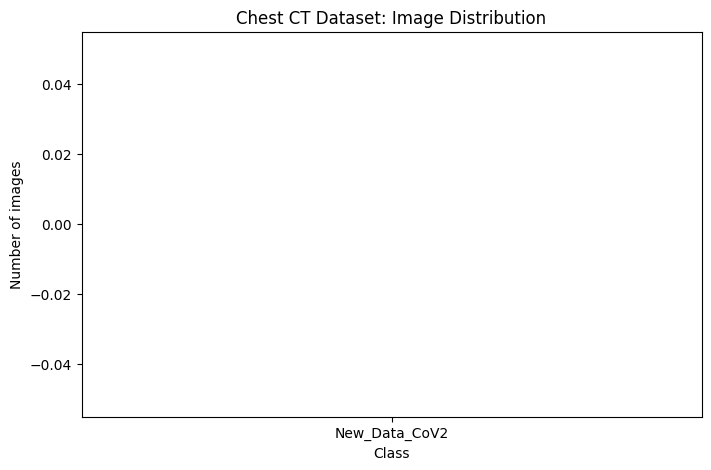

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=class_df,
    x="class",
    y="images"
)

plt.title("Chest CT Dataset: Image Distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.show()

In [ ]:
from pathlib import Path
from PIL import Image
import pandas as pd

records = []

for class_dir in sorted(DATASET_ROOT.iterdir()):

    if not class_dir.is_dir():
        continue

    label = class_dir.name

    for patient_dir in sorted(class_dir.iterdir()):

        if not patient_dir.is_dir():
            continue

        # Class-qualified ID avoids accidentally merging
        # identically numbered folders in different classes.
        patient_id = f"{label}/{patient_dir.name}"

        for img_path in patient_dir.rglob("*.png"):

            try:
                with Image.open(img_path) as img:
                    width, height = img.size
                    mode = img.mode

                records.append({
                    "image_path": str(img_path),
                    "label": label,
                    "patient_id": patient_id,
                    "width": width,
                    "height": height,
                    "mode": mode
                })

            except Exception as e:
                print("Skipped:", img_path, e)

manifest = pd.DataFrame(records)

manifest.to_csv(
    PROCESSED_DIR / "image_manifest.csv",
    index=False
)

print("Manifest created!")
print("Total records:", len(manifest))

display(manifest.head())

Manifest created!
Total records: 4171


,image_path,label,patient_id,width,height,mode
0,/content/drive/MyDrive/chest_ct_classifier/dat...,Covid,Covid/Patient,256,202,RGB
1,/content/drive/MyDrive/chest_ct_classifier/dat...,Covid,Covid/Patient,270,219,RGB
2,/content/drive/MyDrive/chest_ct_classifier/dat...,Covid,Covid/Patient,270,219,RGB
3,/content/drive/MyDrive/chest_ct_classifier/dat...,Covid,Covid/Patient,276,224,RGB
4,/content/drive/MyDrive/chest_ct_classifier/dat...,Covid,Covid/Patient,278,224,RGB


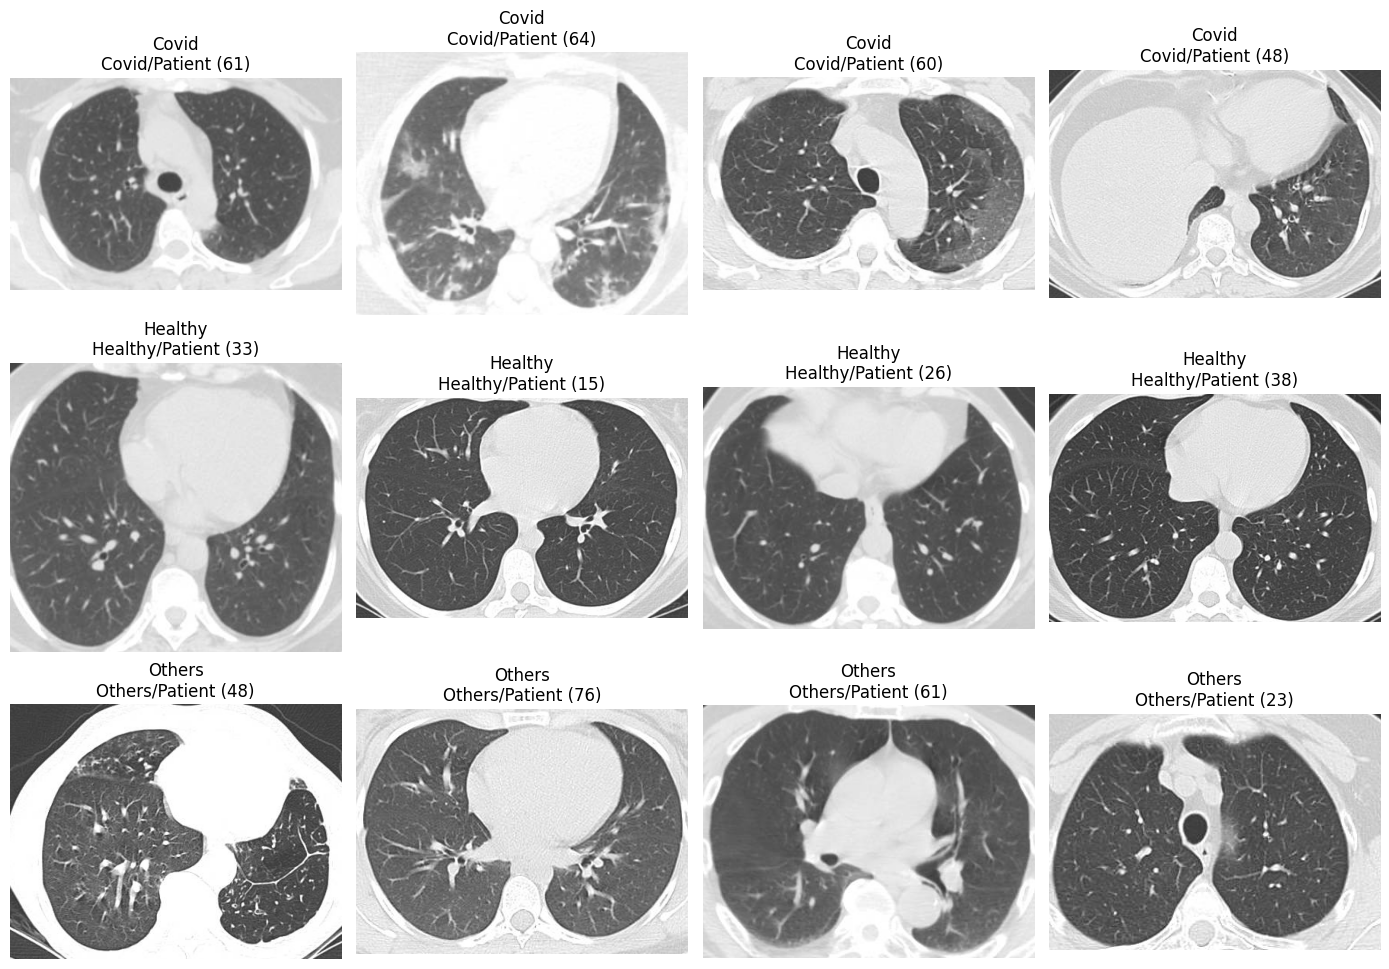

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

classes = ["Covid", "Healthy", "Others"]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for row, class_name in enumerate(classes):

    subset = manifest[
        manifest["label"] == class_name
    ]

    samples = subset.sample(
        min(4, len(subset)),
        random_state=42
    )

    for col, (_, record) in enumerate(samples.iterrows()):

        img = Image.open(record["image_path"])

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(
            f"{class_name}\n{record['patient_id']}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import hashlib
from collections import defaultdict

hash_to_paths = defaultdict(list)

for path in manifest["image_path"]:

    with open(path, "rb") as f:
        digest = hashlib.md5(f.read()).hexdigest()

    hash_to_paths[digest].append(path)

duplicates = {
    digest: paths
    for digest, paths in hash_to_paths.items()
    if len(paths) > 1
}

print("Unique image hashes:", len(hash_to_paths))
print("Duplicate image groups:", len(duplicates))
print(
    "Images involved in duplicate groups:",
    sum(len(paths) for paths in duplicates.values())
)

Unique image hashes: 4169
Duplicate image groups: 2
Images involved in duplicate groups: 4


In [ ]:
# Print all exact duplicate image groups

for i, (digest, paths) in enumerate(duplicates.items(), start=1):
    print(f"\nDuplicate group {i}:")
    for path in paths:
        print(path)


Duplicate group 1:
/content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (71)/32.png
/content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (71)/33.png

Duplicate group 2:
/content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (72)/3.png
/content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (72)/4.png


In [ ]:
# Keep the first image in each exact-duplicate pair.
# Exclude the second image from model development.

duplicate_paths_to_exclude = {
    str(DATASET_ROOT / "Covid/Patient (71)/33.png"),
    str(DATASET_ROOT / "Covid/Patient (72)/4.png")
}

manifest["is_duplicate"] = manifest["image_path"].isin(
    duplicate_paths_to_exclude
)

model_manifest = manifest[~manifest["is_duplicate"]].copy()

print("Original images:", len(manifest))
print("Excluded duplicates:", manifest["is_duplicate"].sum())
print("Images retained:", len(model_manifest))

model_manifest.to_csv(
    PROCESSED_DIR / "image_manifest_clean.csv",
    index=False
)

Original images: 4171
Excluded duplicates: 2
Images retained: 4169


In [ ]:
import pandas as pd

# One row per patient
patient_df = (
    model_manifest[["patient_id", "label"]]
    .drop_duplicates()
    .sort_values("patient_id")
    .reset_index(drop=True)
)

# Check that every patient has exactly one class
label_counts = model_manifest.groupby("patient_id")["label"].nunique()

assert label_counts.max() == 1, "A patient has multiple class labels!"

print("Total patients:", len(patient_df))
print("\nPatients per class:")
print(patient_df["label"].value_counts())
display(patient_df.head())

Total patients: 210

Patients per class:
label
Covid      80
Others     80
Healthy    50
Name: count, dtype: int64


,patient_id,label
0,Covid/Patient,Covid
1,Covid/Patient (10),Covid
2,Covid/Patient (11),Covid
3,Covid/Patient (12),Covid
4,Covid/Patient (13),Covid


In [ ]:
from sklearn.model_selection import train_test_split

# First: 70% train, 30% temporary
train_patients, temp_patients = train_test_split(
    patient_df,
    test_size=0.30,
    random_state=42,
    stratify=patient_df["label"]
)

# Second: divide temporary set equally into validation and test
val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=42,
    stratify=temp_patients["label"]
)

# Assign split names
train_patients = train_patients.assign(split="train")
val_patients = val_patients.assign(split="validation")
test_patients = test_patients.assign(split="test")

# Combine
patient_splits = pd.concat(
    [train_patients, val_patients, test_patients],
    ignore_index=True
)

print("Patient counts:")
print(patient_splits["split"].value_counts())

print("\nClass distribution:")
print(pd.crosstab(
    patient_splits["split"],
    patient_splits["label"]
))

Patient counts:
split
train         147
test           32
validation     31
Name: count, dtype: int64

Class distribution:
label       Covid  Healthy  Others
split                             
test           12        8      12
train          56       35      56
validation     12        7      12


In [ ]:
split_manifest = model_manifest.merge(
    patient_splits[["patient_id", "split"]],
    on="patient_id",
    how="left",
    validate="many_to_one"
)

assert split_manifest["split"].notna().all()

print("Total images:", len(split_manifest))

print("\nImages per split:")
print(split_manifest["split"].value_counts())

print("\nImages per class per split:")
print(pd.crosstab(
    split_manifest["split"],
    split_manifest["label"]
))

Total images: 4169

Images per split:
split
train         2932
validation     622
test           615
Name: count, dtype: int64

Images per class per split:
label       Covid  Healthy  Others
split                             
test          316      129     170
train        1517      521     894
validation    332      107     183


In [ ]:
train_ids = set(train_patients["patient_id"])
val_ids = set(val_patients["patient_id"])
test_ids = set(test_patients["patient_id"])

print("Train-validation overlap:", len(train_ids & val_ids))
print("Train-test overlap:", len(train_ids & test_ids))
print("Validation-test overlap:", len(val_ids & test_ids))

assert len(train_ids & val_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0

print("\nAll patient-level split checks passed!")

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

All patient-level split checks passed!


In [ ]:
split_manifest.to_csv(
    PROCESSED_DIR / "final_split_manifest.csv",
    index=False
)

patient_splits.to_csv(
    PROCESSED_DIR / "patient_splits.csv",
    index=False
)

print("Saved both split files successfully!")

Saved both split files successfully!


In [ ]:
import torch
from torchvision import transforms

IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=7),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations ready.")

Image transformations ready.


In [ ]:
from torch.utils.data import Dataset
from PIL import Image
import pandas as pd

class ChestCTDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

        self.class_to_idx = {
            "Covid": 0,
            "Healthy": 1,
            "Others": 2
        }

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["image_path"]
        label = self.class_to_idx[row["label"]]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
train_df = split_manifest[
    split_manifest["split"] == "train"
].copy()

val_df = split_manifest[
    split_manifest["split"] == "validation"
].copy()

test_df = split_manifest[
    split_manifest["split"] == "test"
].copy()

train_dataset = ChestCTDataset(
    train_df,
    transform=train_transform
)

val_dataset = ChestCTDataset(
    val_df,
    transform=eval_transform
)

test_dataset = ChestCTDataset(
    test_df,
    transform=eval_transform
)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Train images: 2932
Validation images: 622
Test images: 615


In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully!
Training batches: 92
Validation batches: 20
Testing batches: 20


Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels: [0, 2, 2, 1, 2, 1, 0, 0, 0, 0]


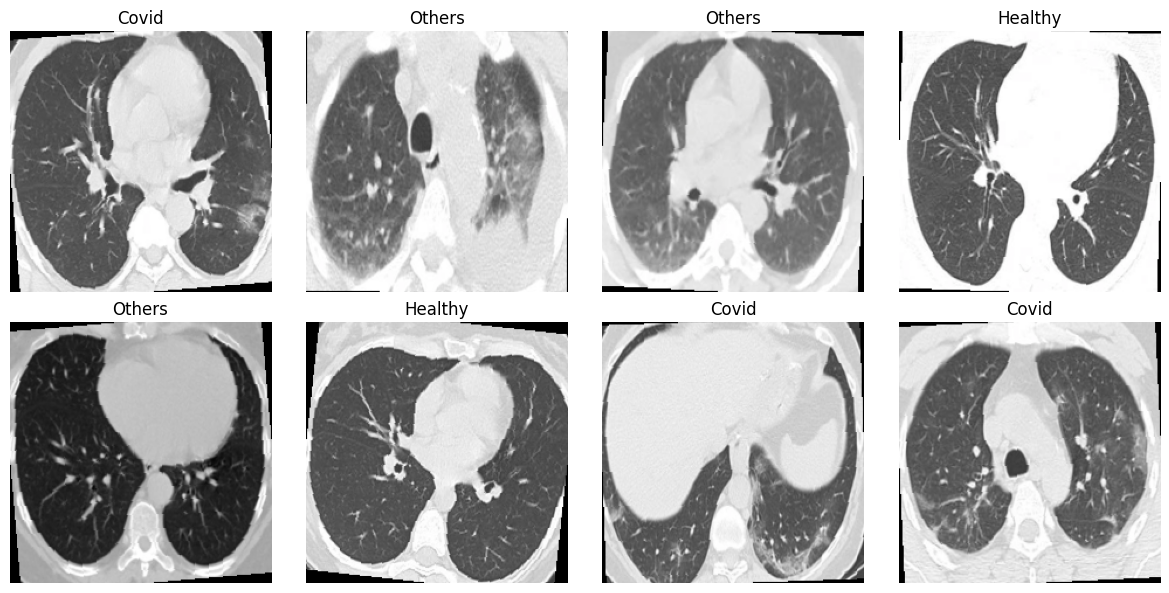

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

CLASS_NAMES = ["Covid", "Healthy", "Others"]

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10].tolist())

# Undo normalization for visualisation
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

display_images = images[:8] * std + mean
display_images = display_images.clamp(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    img = display_images[i].permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(CLASS_NAMES[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# Load pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Freeze pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace final layer for our 3 classes
num_features = model.fc.in_features

model.fc = nn.Linear(num_features, 3)

# Move model to GPU
model = model.to(device)

print(model.fc)
print("Model loaded successfully!")
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 165MB/s]


Linear(in_features=512, out_features=3, bias=True)
Model loaded successfully!
Trainable parameters: 1539


In [ ]:
import numpy as np
import torch
from sklearn.utils.class_weight import compute_class_weight

# Labels from training images only
train_labels = train_df["label"].map({
    "Covid": 0,
    "Healthy": 1,
    "Others": 2
}).values

classes = np.array([0, 1, 2])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:")
for name, weight in zip(CLASS_NAMES, class_weights):
    print(f"{name}: {weight.item():.4f}")

Class weights:
Covid: 0.6443
Healthy: 1.8759
Others: 1.0932


In [ ]:
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("Loss function and optimizer configured.")

Loss function and optimizer configured.


In [ ]:
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

def run_epoch(model, loader, criterion, optimizer=None):

    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    for images, labels in tqdm(loader, leave=False):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    accuracy = accuracy_score(all_labels, all_predictions)

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, accuracy, macro_f1

In [ ]:
import copy
from pathlib import Path

NUM_EPOCHS = 15
PATIENCE = 4

MODELS_DIR.mkdir(parents=True, exist_ok=True)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

best_val_f1 = -1
epochs_without_improvement = 0

history = []

best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")

    train_loss, train_acc, train_f1 = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc, val_f1 = run_epoch(
        model,
        val_loader,
        criterion
    )

    scheduler.step(val_f1)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Train Macro-F1: {train_f1:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f} | "
        f"Val Macro-F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_model_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_model_state,
            MODELS_DIR / "resnet18_phase1_best.pth"
        )

        epochs_without_improvement = 0
        print("Best model saved!")

    else:
        epochs_without_improvement += 1
        print("No improvement.")

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

# Restore best model
model.load_state_dict(best_model_state)

history_df = pd.DataFrame(history)

history_df.to_csv(
    RESULTS_DIR / "phase1_training_history.csv",
    index=False
)

print("\nPhase 1 complete!")
print("Best validation macro-F1:", round(best_val_f1, 4))


Epoch 1/15


  0%|          | 0/92 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

Train Loss: 0.9651 | Train Accuracy: 0.5044 | Train Macro-F1: 0.4783
Val Loss: 0.9797 | Val Accuracy: 0.5273 | Val Macro-F1: 0.5367
Best model saved!

Epoch 2/15


  0%|          | 0/92 [00:00<?, ?it/s]

Exception ignored in: self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7b4f716e4e00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b4f716e4e00>    self._shutdown_workers()

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
        if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
        assert self._parent_pid == os.getpid(), 'can only test a child process'if w.is_alive():

AssertionError  File "/usr/lib/python3.13/multiprocessing/proce

... (30 outputs left out)

Train Loss: 0.6440 | Train Accuracy: 0.7176 | Train Macro-F1: 0.6971
Val Loss: 0.7130 | Val Accuracy: 0.6865 | Val Macro-F1: 0.6854
No improvement.

Epoch 10/15


  0%|          | 0/92 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

Train Loss: 0.6128 | Train Accuracy: 0.7428 | Train Macro-F1: 0.7244
Val Loss: 0.6918 | Val Accuracy: 0.6881 | Val Macro-F1: 0.6833
No improvement.
Early stopping triggered.

Phase 1 complete!
Best validation macro-F1: 0.6954


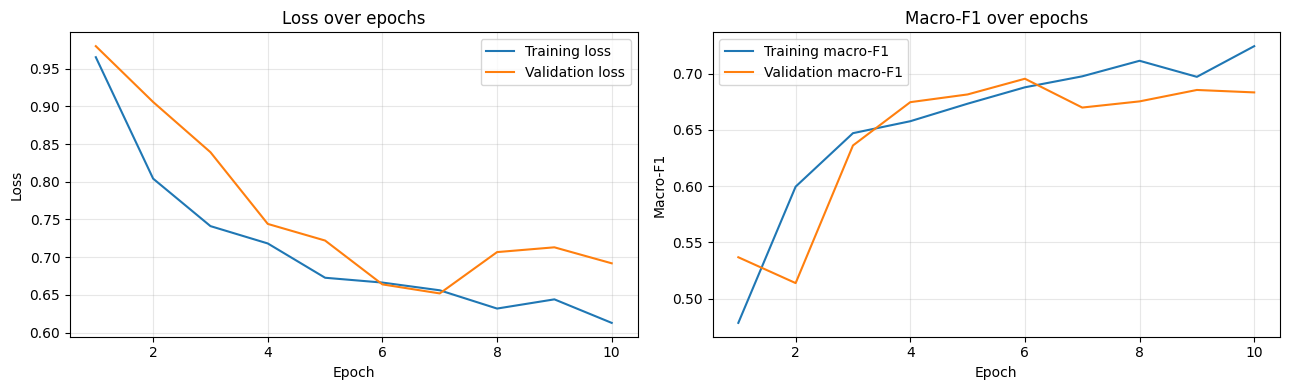

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"],
             label="Training loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"],
             label="Validation loss")
axes[0].set_title("Loss over epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_df["epoch"], history_df["train_macro_f1"],
             label="Training macro-F1")
axes[1].plot(history_df["epoch"], history_df["val_macro_f1"],
             label="Validation macro-F1")
axes[1].set_title("Macro-F1 over epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np

checkpoint_path = MODELS_DIR / "resnet18_phase1_best.pth"

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

model.eval()

all_preds = []
all_targets = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_targets.extend(labels.numpy())

print(classification_report(
    all_targets,
    all_preds,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

       Covid     0.8357    0.7199    0.7735       332
     Healthy     0.6260    0.7664    0.6891       107
      Others     0.5902    0.6612    0.6237       183

    accuracy                         0.7106       622
   macro avg     0.6840    0.7158    0.6954       622
weighted avg     0.7274    0.7106    0.7149       622



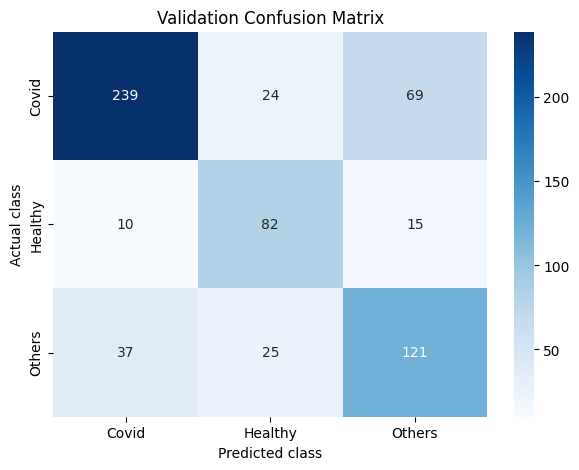

In [ ]:
cm = confusion_matrix(
    all_targets,
    all_preds,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Validation Confusion Matrix")
plt.show()

In [ ]:
# Restore the best Phase 1 model
checkpoint_path = MODELS_DIR / "resnet18_phase1_best.pth"

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

# Freeze the entire network first
for param in model.parameters():
    param.requires_grad = False

# Unfreeze only the final ResNet block
for param in model.layer4.parameters():
    param.requires_grad = True

# Unfreeze the classification head
for param in model.fc.parameters():
    param.requires_grad = True

print("Phase 2 trainable parameters:")

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

Phase 2 trainable parameters:
layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


In [ ]:
optimizer = torch.optim.AdamW(
    [
        {
            "params": model.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.fc.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)


In [ ]:
from sklearn.metrics import f1_score
import numpy as np
import torch.nn as nn

def run_epoch(model, loader, criterion, optimizer=None):

    training = optimizer is not None

    if training:
        model.train()

        # Keep BatchNorm running statistics frozen
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()

    else:
        model.eval()

    total_loss = 0
    all_preds = []
    all_targets = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            outputs = model(images)

            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.detach().cpu().numpy())
        all_targets.extend(labels.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    accuracy = np.mean(
        np.array(all_preds) == np.array(all_targets)
    )

    macro_f1 = f1_score(
        all_targets,
        all_preds,
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1

In [ ]:
from pathlib import Path
import pandas as pd

EPOCHS = 10
PATIENCE = 4

best_val_f1 = 0
epochs_without_improvement = 0

phase2_history = []

best_checkpoint = MODELS_DIR / "resnet18_phase2_best.pth"

for epoch in range(EPOCHS):

    train_loss, train_acc, train_f1 = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_acc, val_f1 = run_epoch(
        model, val_loader, criterion
    )

    scheduler.step(val_f1)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Train F1: {train_f1:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f} | Val F1:   {val_f1:.4f}")

    phase2_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        epochs_without_improvement = 0

        torch.save(model.state_dict(), best_checkpoint)

        print("Best Phase 2 model saved!")

    else:
        epochs_without_improvement += 1
        print("No improvement.")

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

phase2_history_df = pd.DataFrame(phase2_history)

phase2_history_df.to_csv(
    RESULTS_DIR / "phase2_training_history.csv",
    index=False
)

print("\nBest Phase 2 Validation Macro-F1:", round(best_val_f1, 4))


Epoch 1/10
Train Loss: 0.5872 | Train Acc: 0.7422 | Train F1: 0.7215
Val Loss:   0.5689 | Val Acc:   0.7331 | Val F1:   0.7040
Best Phase 2 model saved!

Epoch 2/10
Train Loss: 0.4837 | Train Acc: 0.7984 | Train F1: 0.7826
Val Loss:   0.5545 | Val Acc:   0.7653 | Val F1:   0.7489
Best Phase 2 model saved!

Epoch 3/10
Train Loss: 0.4067 | Train Acc: 0.8244 | Train F1: 0.8108
Val Loss:   0.6067 | Val Acc:   0.7492 | Val F1:   0.7389
No improvement.

Epoch 4/10
Train Loss: 0.3525 | Train Acc: 0.8571 | Train F1: 0.8459
Val Loss:   0.5403 | Val Acc:   0.7653 | Val F1:   0.7343
No improvement.

Epoch 5/10
Train Loss: 0.3013 | Train Acc: 0.8789 | Train F1: 0.8720
Val Loss:   0.5875 | Val Acc:   0.7637 | Val F1:   0.7539
Best Phase 2 model saved!

Epoch 6/10
Train Loss: 0.2776 | Train Acc: 0.8915 | Train F1: 0.8857
Val Loss:   0.5631 | Val Acc:   0.7894 | Val F1:   0.7764
Best Phase 2 model saved!

Epoch 7/10
Train Loss: 0.2670 | Train Acc: 0.8902 | Train F1: 0.8826
Val Loss:   0.6809 | Val A

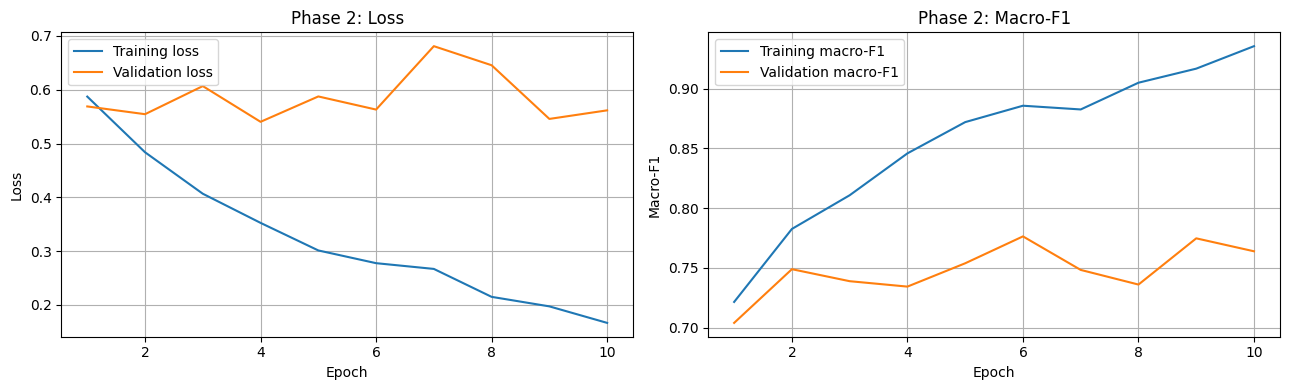

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    phase2_history_df["epoch"],
    phase2_history_df["train_loss"],
    label="Training loss"
)

axes[0].plot(
    phase2_history_df["epoch"],
    phase2_history_df["val_loss"],
    label="Validation loss"
)

axes[0].set_title("Phase 2: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    phase2_history_df["epoch"],
    phase2_history_df["train_macro_f1"],
    label="Training macro-F1"
)

axes[1].plot(
    phase2_history_df["epoch"],
    phase2_history_df["val_macro_f1"],
    label="Validation macro-F1"
)

axes[1].set_title("Phase 2: Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Phase 2 Validation Classification Report:

              precision    recall  f1-score   support

       Covid     0.8904    0.8072    0.8468       332
     Healthy     0.7377    0.8411    0.7860       107
      Others     0.6683    0.7268    0.6963       183

    accuracy                         0.7894       622
   macro avg     0.7655    0.7917    0.7764       622
weighted avg     0.7988    0.7894    0.7921       622



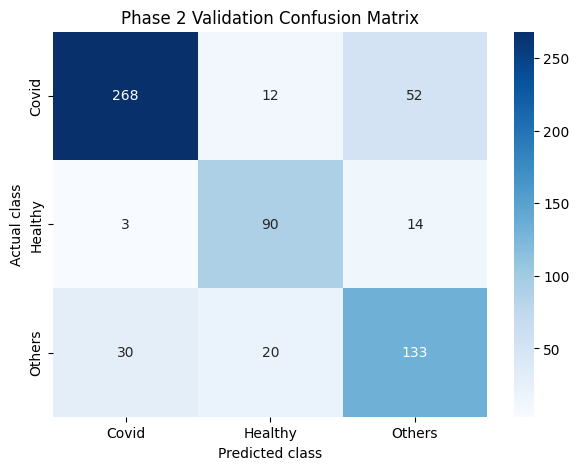

In [ ]:
# Load best Phase 2 checkpoint
checkpoint_path = MODELS_DIR / "resnet18_phase2_best.pth"

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

model.eval()

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_targets.extend(labels.numpy())

print("Phase 2 Validation Classification Report:\n")

print(
    classification_report(
        all_targets,
        all_preds,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(
    all_targets,
    all_preds
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Phase 2 Validation Confusion Matrix")

plt.show()

Patient-level Classification Report:

              precision    recall  f1-score   support

       Covid     1.0000    0.8333    0.9091        12
     Healthy     0.8571    0.8571    0.8571         7
      Others     0.7857    0.9167    0.8462        12

    accuracy                         0.8710        31
   macro avg     0.8810    0.8690    0.8708        31
weighted avg     0.8848    0.8710    0.8730        31

Number of validation patients: 31


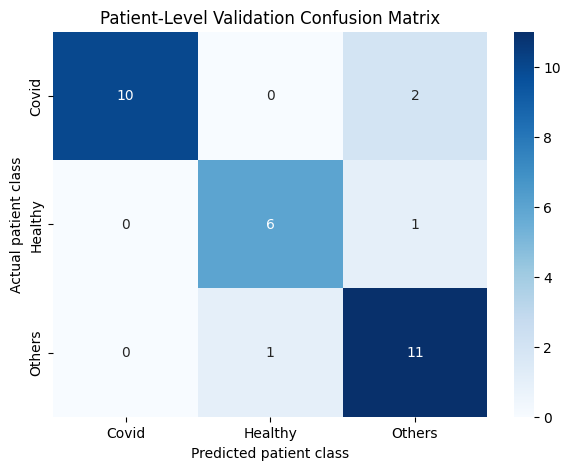

In [ ]:
import pandas as pd
import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix

# Restore best Phase 2 model
model.load_state_dict(
    torch.load(
        MODELS_DIR / "resnet18_phase2_best.pth",
        map_location=device
    )
)

model.eval()

# Validation dataframe must be in the same order
# as the non-shuffled validation DataLoader
val_df = val_df.reset_index(drop=True)

all_probabilities = []
all_targets = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_targets.extend(
            labels.numpy()
        )

# Construct slice-level predictions
slice_results = val_df[
    ["patient_id", "label"]
].copy()

slice_results["true_label"] = all_targets

probabilities_array = np.array(all_probabilities)

slice_results["prob_covid"] = probabilities_array[:, 0]
slice_results["prob_healthy"] = probabilities_array[:, 1]
slice_results["prob_others"] = probabilities_array[:, 2]

# Aggregate slice probabilities by patient
patient_results = (
    slice_results
    .groupby("patient_id")
    .agg({
        "label": "first",
        "true_label": "first",
        "prob_covid": "mean",
        "prob_healthy": "mean",
        "prob_others": "mean"
    })
    .reset_index()
)

# Check that every patient's slices have one consistent label
assert (
    slice_results.groupby("patient_id")["true_label"].nunique().max() == 1
)

# Patient-level predictions
patient_probabilities = patient_results[
    ["prob_covid", "prob_healthy", "prob_others"]
].values

patient_predictions = patient_probabilities.argmax(axis=1)

class_names = ["Covid", "Healthy", "Others"]

true_patient_labels = patient_results["true_label"].values

print("Patient-level Classification Report:\n")

print(
    classification_report(
        true_patient_labels,
        patient_predictions,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print("Number of validation patients:", len(patient_results))

# Patient-level confusion matrix
cm_patient = confusion_matrix(
    true_patient_labels,
    patient_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_patient,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted patient class")
plt.ylabel("Actual patient class")
plt.title("Patient-Level Validation Confusion Matrix")

plt.show()

Patient-level Classification Report:

              precision    recall  f1-score   support

       Covid     1.0000    0.8333    0.9091        12
     Healthy     0.8571    0.8571    0.8571         7
      Others     0.7857    0.9167    0.8462        12

    accuracy                         0.8710        31
   macro avg     0.8810    0.8690    0.8708        31
weighted avg     0.8848    0.8710    0.8730        31

Number of validation patients: 31


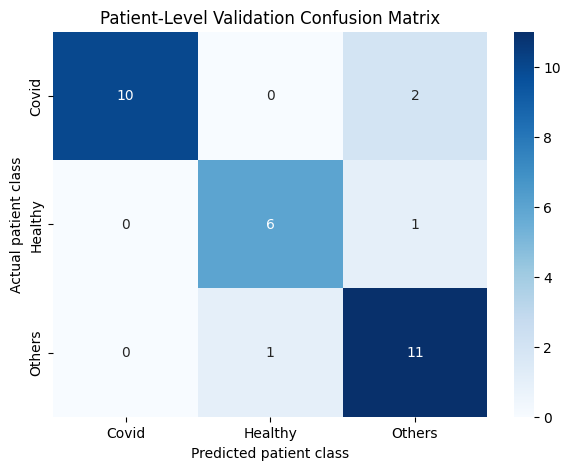

In [ ]:
import pandas as pd
import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix

# Restore best Phase 2 model
model.load_state_dict(
    torch.load(
        MODELS_DIR / "resnet18_phase2_best.pth",
        map_location=device
    )
)

model.eval()

# Validation dataframe must be in the same order
# as the non-shuffled validation DataLoader
val_df = val_df.reset_index(drop=True)

all_probabilities = []
all_targets = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_targets.extend(
            labels.numpy()
        )

# Construct slice-level predictions
slice_results = val_df[
    ["patient_id", "label"]
].copy()

slice_results["true_label"] = all_targets

probabilities_array = np.array(all_probabilities)

slice_results["prob_covid"] = probabilities_array[:, 0]
slice_results["prob_healthy"] = probabilities_array[:, 1]
slice_results["prob_others"] = probabilities_array[:, 2]

# Aggregate slice probabilities by patient
patient_results = (
    slice_results
    .groupby("patient_id")
    .agg({
        "label": "first",
        "true_label": "first",
        "prob_covid": "mean",
        "prob_healthy": "mean",
        "prob_others": "mean"
    })
    .reset_index()
)

# Check that every patient's slices have one consistent label
assert (
    slice_results.groupby("patient_id")["true_label"].nunique().max() == 1
)

# Patient-level predictions
patient_probabilities = patient_results[
    ["prob_covid", "prob_healthy", "prob_others"]
].values

patient_predictions = patient_probabilities.argmax(axis=1)

class_names = ["Covid", "Healthy", "Others"]

true_patient_labels = patient_results["true_label"].values

print("Patient-level Classification Report:\n")

print(
    classification_report(
        true_patient_labels,
        patient_predictions,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

print("Number of validation patients:", len(patient_results))

# Patient-level confusion matrix
cm_patient = confusion_matrix(
    true_patient_labels,
    patient_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_patient,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted patient class")
plt.ylabel("Actual patient class")
plt.title("Patient-Level Validation Confusion Matrix")

plt.show()

TEST SET — SLICE LEVEL
              precision    recall  f1-score   support

       Covid     0.8467    0.7342    0.7864       316
     Healthy     0.5290    0.6357    0.5775       129
      Others     0.5860    0.6412    0.6124       170

    accuracy                         0.6878       615
   macro avg     0.6539    0.6703    0.6588       615
weighted avg     0.7080    0.6878    0.6945       615


TEST SET — PATIENT LEVEL
Number of test patients: 32
              precision    recall  f1-score   support

       Covid     0.9000    0.7500    0.8182        12
     Healthy     0.6667    0.7500    0.7059         8
      Others     0.7692    0.8333    0.8000        12

    accuracy                         0.7812        32
   macro avg     0.7786    0.7778    0.7747        32
weighted avg     0.7926    0.7812    0.7833        32



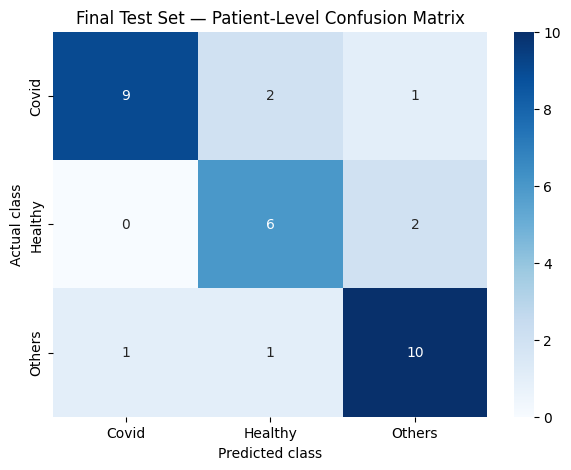

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch

# Load the best Phase 2 model
model.load_state_dict(
    torch.load(
        MODELS_DIR / "resnet18_phase2_best.pth",
        map_location=device
    )
)

model.eval()

# Reset test dataframe index
test_df = test_df.reset_index(drop=True)

all_probabilities = []
all_targets = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_targets.extend(labels.numpy())

# Check slice-level alignment
assert len(test_df) == len(all_targets)

# Create test predictions dataframe
test_results = test_df[
    ["patient_id", "label"]
].copy()

test_results["true_label"] = all_targets

probs = np.array(all_probabilities)

test_results["prob_covid"] = probs[:, 0]
test_results["prob_healthy"] = probs[:, 1]
test_results["prob_others"] = probs[:, 2]

# Slice-level evaluation
slice_preds = probs.argmax(axis=1)

print("TEST SET — SLICE LEVEL")
print(classification_report(
    all_targets,
    slice_preds,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

# Aggregate predictions at patient level
patient_test_results = (
    test_results
    .groupby("patient_id")
    .agg({
        "true_label": "first",
        "prob_covid": "mean",
        "prob_healthy": "mean",
        "prob_others": "mean"
    })
    .reset_index()
)

# Confirm consistent labels within patients
assert (
    test_results.groupby("patient_id")["true_label"]
    .nunique().max() == 1
)

patient_probs = patient_test_results[
    ["prob_covid", "prob_healthy", "prob_others"]
].values

patient_preds = patient_probs.argmax(axis=1)
patient_targets = patient_test_results["true_label"].values

print("\nTEST SET — PATIENT LEVEL")
print("Number of test patients:", len(patient_test_results))

print(classification_report(
    patient_targets,
    patient_preds,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

# Patient-level confusion matrix
cm = confusion_matrix(patient_targets, patient_preds)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Final Test Set — Patient-Level Confusion Matrix")
plt.show()

In [ ]:
import torch
import torch.nn.functional as F
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

checkpoint_path = MODELS_DIR / "resnet18_phase2_best.pth"

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

model.eval()

CLASS_NAMES = ["Covid", "Healthy", "Others"]

print("Best Phase 2 model loaded.")

Best Phase 2 model loaded.


In [ ]:
def generate_gradcam(model, image_tensor, target_class=None):

    model.eval()

    activations = []
    gradients = []

    target_layer = model.layer4[-1]

    # Capture feature maps and their gradients
    def forward_hook(module, inputs, output):
        activations.append(output)
        output.register_hook(
            lambda grad: gradients.append(grad)
        )

    hook = target_layer.register_forward_hook(forward_hook)

    model.zero_grad()

    image_tensor = image_tensor.unsqueeze(0).to(device)

    # Forward pass
    output = model(image_tensor)

    predicted_class = output.argmax(dim=1).item()

    # By default, explain the predicted class
    if target_class is None:
        target_class = predicted_class

    # Backpropagate the selected class score
    score = output[0, target_class]
    score.backward()

    # Extract feature maps and gradients
    feature_maps = activations[0]
    grads = gradients[0]

    # Average gradients spatially to obtain channel weights
    weights = grads.mean(dim=(2, 3), keepdim=True)

    # Weighted combination of feature maps
    cam = (weights * feature_maps).sum(dim=1)

    # Retain positive contributions
    cam = F.relu(cam)

    # Resize heatmap to input image size
    cam = F.interpolate(
        cam.unsqueeze(1),
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = cam.squeeze().detach().cpu().numpy()

    # Normalize heatmap
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)

    hook.remove()

    return cam, predicted_class

In [ ]:
# Make sure test_results and probs exist from the test evaluation

test_results = test_results.reset_index(drop=True).copy()

test_results["predicted_idx"] = probs.argmax(axis=1)

test_results["predicted_label"] = [
    CLASS_NAMES[i] for i in test_results["predicted_idx"]
]

test_results["correct"] = (
    test_results["true_label"] ==
    test_results["predicted_idx"]
)

correct_indices = test_results.index[
    test_results["correct"]
].tolist()

incorrect_indices = test_results.index[
    ~test_results["correct"]
].tolist()

print("Correctly classified slices:", len(correct_indices))
print("Incorrectly classified slices:", len(incorrect_indices))

Correctly classified slices: 423
Incorrectly classified slices: 192


In [ ]:
# Rebuild test_results while retaining image paths
test_results = test_df[
    ["image_path", "patient_id", "label"]
].copy()

test_results = test_results.reset_index(drop=True)

# Add actual and predicted labels
test_results["true_label"] = all_targets
test_results["predicted_idx"] = probs.argmax(axis=1)

test_results["predicted_label"] = [
    CLASS_NAMES[i] for i in test_results["predicted_idx"]
]

test_results["correct"] = (
    test_results["true_label"] ==
    test_results["predicted_idx"]
)

print("Columns:", test_results.columns.tolist())
print("Total test images:", len(test_results))

Columns: ['image_path', 'patient_id', 'label', 'true_label', 'predicted_idx', 'predicted_label', 'correct']
Total test images: 615


In [ ]:
correct_indices = test_results.index[
    test_results["correct"]
].tolist()

incorrect_indices = test_results.index[
    ~test_results["correct"]
].tolist()

print("Correct predictions:", len(correct_indices))
print("Incorrect predictions:", len(incorrect_indices))

Correct predictions: 423
Incorrect predictions: 192


Image: /content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (11)/AnotaΓÇí╓╢o 2020-04-28 142924.png
Actual: Covid | Predicted: Covid

Image: /content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (11)/AnotaΓÇí╓╢o 2020-04-28 143956.png
Actual: Covid | Predicted: Covid

Image: /content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (22)/AnotaΓÇí╓╢o 2020-04-29 190620.png
Actual: Covid | Predicted: Others



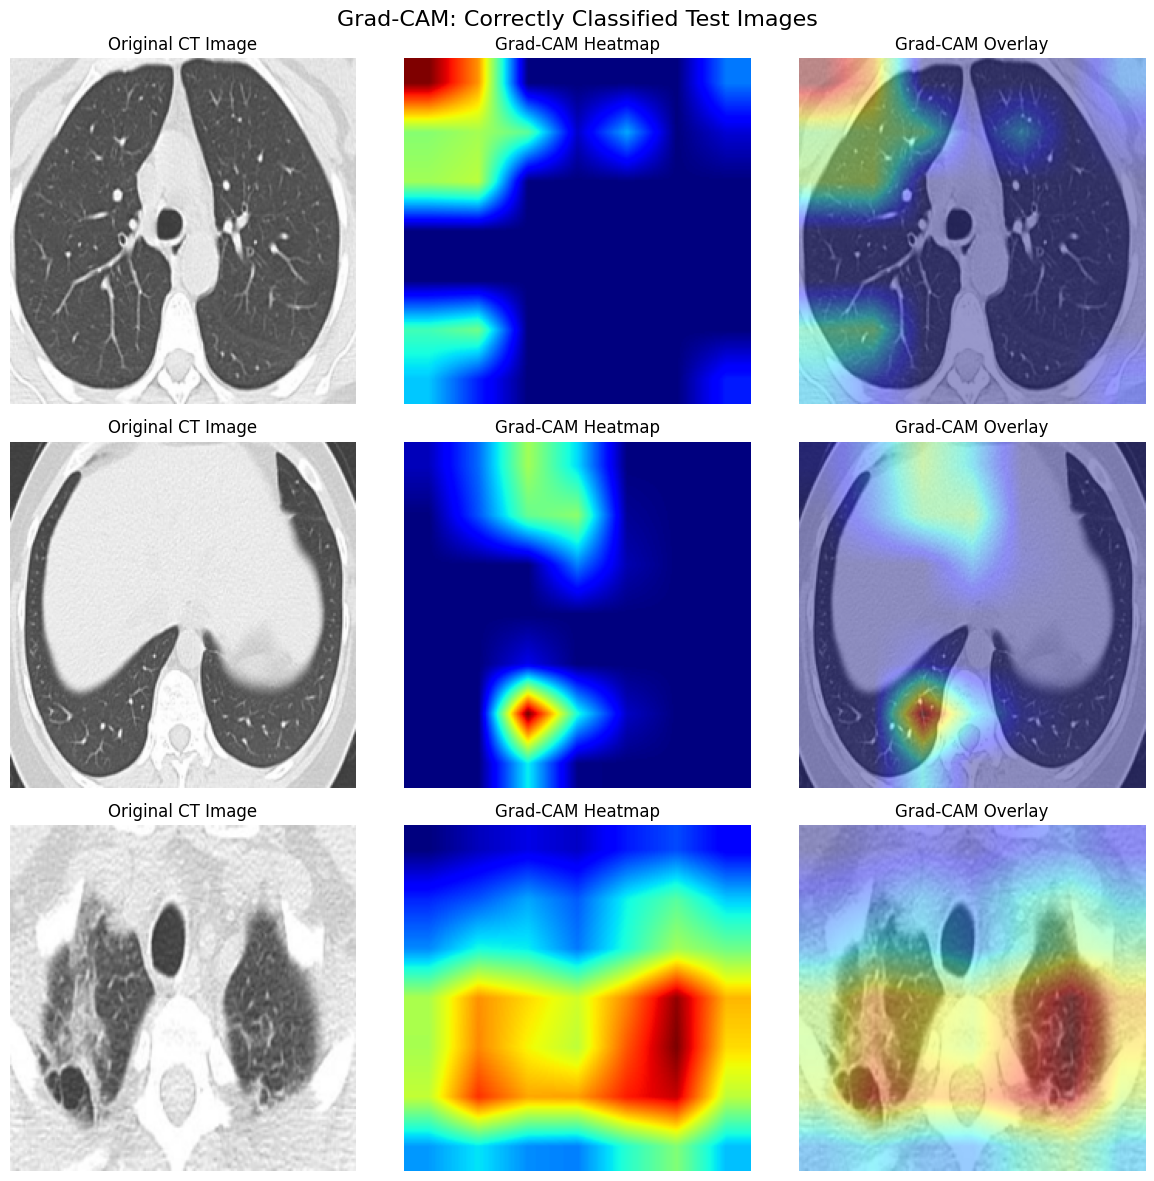

Image: /content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (11)/AnotaΓÇí╓╢o 2020-04-28 142601.png
Actual: Covid | Predicted: Healthy

Image: /content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (11)/AnotaΓÇí╓╢o 2020-04-28 142702.png
Actual: Covid | Predicted: Healthy

Image: /content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (11)/AnotaΓÇí╓╢o 2020-04-28 142752.png
Actual: Covid | Predicted: Healthy



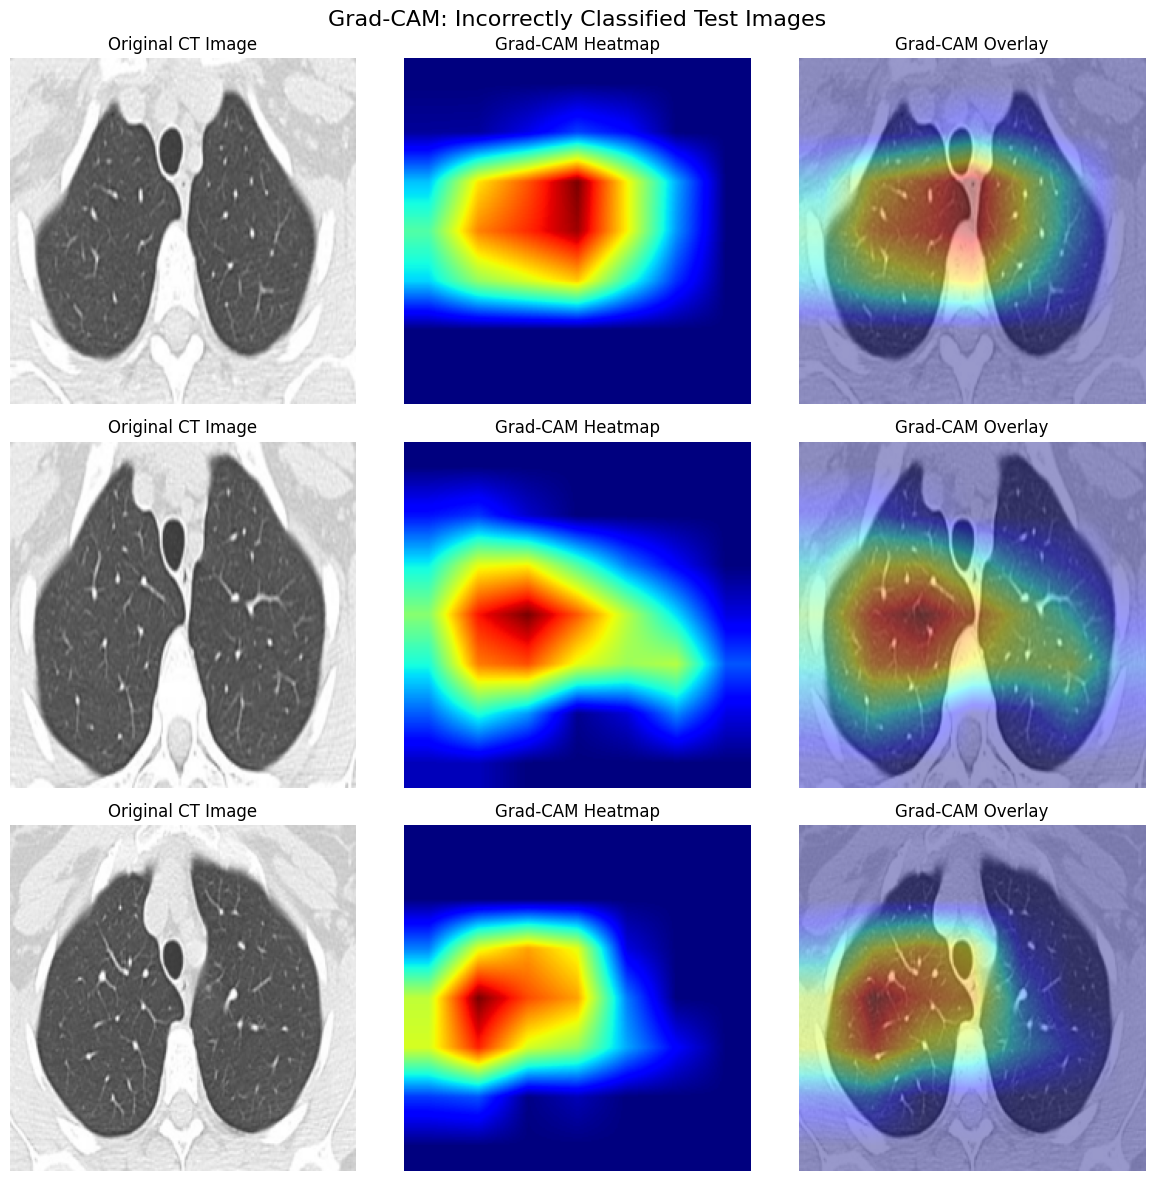

In [ ]:
def show_gradcam_examples(indices, title, max_examples=3):

    selected_indices = indices[:max_examples]

    if len(selected_indices) == 0:
        print(f"No examples available for: {title}")
        return

    fig, axes = plt.subplots(
        len(selected_indices),
        3,
        figsize=(12, 4 * len(selected_indices))
    )

    if len(selected_indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    fig.suptitle(title, fontsize=16)

    for row, idx in enumerate(selected_indices):

        record = test_results.iloc[idx]

        image_path = record["image_path"]

        # Load original image
        original_image = Image.open(
            image_path
        ).convert("RGB").resize((224, 224))

        # Apply evaluation transform
        image_tensor = eval_transform(original_image)

        # Generate Grad-CAM for the predicted class
        cam, predicted_class = generate_gradcam(
            model,
            image_tensor
        )

        actual_label = CLASS_NAMES[int(record["true_label"])]
        predicted_label = CLASS_NAMES[predicted_class]

        # Original image
        axes[row, 0].imshow(original_image)
        axes[row, 0].set_title("Original CT Image")

        # Heatmap
        axes[row, 1].imshow(cam, cmap="jet")
        axes[row, 1].set_title("Grad-CAM Heatmap")

        # Overlay
        axes[row, 2].imshow(original_image)
        axes[row, 2].imshow(
            cam,
            cmap="jet",
            alpha=0.4
        )

        axes[row, 2].set_title("Grad-CAM Overlay")

        for ax in axes[row]:
            ax.axis("off")

        print(
            f"Image: {image_path}\n"
            f"Actual: {actual_label} | "
            f"Predicted: {predicted_label}\n"
        )

    plt.tight_layout()
    plt.show()


# Correct predictions
show_gradcam_examples(
    correct_indices,
    "Grad-CAM: Correctly Classified Test Images"
)

# Incorrect predictions
show_gradcam_examples(
    incorrect_indices,
    "Grad-CAM: Incorrectly Classified Test Images"
)

In [ ]:
# Display metadata for the first three incorrect examples

for idx in incorrect_indices[:3]:

    row = test_results.iloc[idx]

    print("----------------------------------")
    print("Image:", row["image_path"])
    print("Patient:", row["patient_id"])
    print("Actual class:", CLASS_NAMES[int(row["true_label"])])
    print("Predicted class:", row["predicted_label"])

    print("Prediction probabilities:")

    for class_name, probability in zip(
        CLASS_NAMES,
        probs[idx]
    ):
        print(f"{class_name}: {probability:.4f}")

----------------------------------
Image: /content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (11)/AnotaΓÇí╓╢o 2020-04-28 142601.png
Patient: Covid/Patient (11)
Actual class: Covid
Predicted class: Healthy
Prediction probabilities:
Covid: 0.0235
Healthy: 0.9015
Others: 0.0750
----------------------------------
Image: /content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (11)/AnotaΓÇí╓╢o 2020-04-28 142702.png
Patient: Covid/Patient (11)
Actual class: Covid
Predicted class: Healthy
Prediction probabilities:
Covid: 0.0127
Healthy: 0.9597
Others: 0.0276
----------------------------------
Image: /content/drive/MyDrive/chest_ct_classifier/data/raw/extracted/New_Data_CoV2/Covid/Patient (11)/AnotaΓÇí╓╢o 2020-04-28 142752.png
Patient: Covid/Patient (11)
Actual class: Covid
Predicted class: Healthy
Prediction probabilities:
Covid: 0.2249
Healthy: 0.6910
Others: 0.0840


In [ ]:
# Calculate confidence and prediction correctness

test_results["confidence"] = probs.max(axis=1)

print("Average confidence — correct predictions:")
print(
    test_results.loc[
        test_results["correct"], "confidence"
    ].mean()
)

print("\nAverage confidence — incorrect predictions:")
print(
    test_results.loc[
        ~test_results["correct"], "confidence"
    ].mean()
)

print("\nMost confident incorrect predictions:")

display(
    test_results.loc[
        ~test_results["correct"]
    ].sort_values(
        "confidence",
        ascending=False
    )[
        [
            "patient_id",
            "label",
            "predicted_label",
            "confidence",
            "image_path"
        ]
    ].head(10)
)

Average confidence — correct predictions:
0.8795198

Average confidence — incorrect predictions:
0.7504204

Most confident incorrect predictions:


,patient_id,label,predicted_label,confidence,image_path
610,Others/Patient (69),Others,Covid,0.997881,/content/drive/MyDrive/chest_ct_classifier/dat...
608,Others/Patient (69),Others,Covid,0.997665,/content/drive/MyDrive/chest_ct_classifier/dat...
18,Covid/Patient (11),Covid,Healthy,0.996315,/content/drive/MyDrive/chest_ct_classifier/dat...
373,Healthy/Patient (31),Healthy,Others,0.991680,/content/drive/MyDrive/chest_ct_classifier/dat...
7,Covid/Patient (11),Covid,Healthy,0.991199,/content/drive/MyDrive/chest_ct_classifier/dat...
152,Covid/Patient (49),Covid,Healthy,0.988216,/content/drive/MyDrive/chest_ct_classifier/dat...
609,Others/Patient (69),Others,Covid,0.987583,/content/drive/MyDrive/chest_ct_classifier/dat...
481,Others/Patient (22),Others,Covid,0.987555,/content/drive/MyDrive/chest_ct_classifier/dat...
14,Covid/Patient (11),Covid,Healthy,0.985172,/content/drive/MyDrive/chest_ct_classifier/dat...
605,Others/Patient (69),Others,Covid,0.974268,/content/drive/MyDrive/chest_ct_classifier/dat...


In [ ]:
# Patient-level breakdown of test-set errors

# Re-add probability columns from the original test evaluation 'probs' array
test_results["prob_covid"] = probs[:, 0]
test_results["prob_healthy"] = probs[:, 1]
test_results["prob_others"] = probs[:, 2]

patient_error_analysis = (
    test_results
    .groupby("patient_id")
    .agg(
        actual_class=("true_label", "first"),
        total_slices=("image_path", "count"),
        correct_slices=("correct", "sum"),
        mean_confidence=("confidence", "mean"),
        covid_probability=("prob_covid", "mean"),
        healthy_probability=("prob_healthy", "mean"),
        others_probability=("prob_others", "mean")
    )
    .reset_index()
)

patient_error_analysis["slice_accuracy"] = (
    patient_error_analysis["correct_slices"] /
    patient_error_analysis["total_slices"]
)

patient_error_analysis["predicted_class"] = (
    patient_error_analysis[
        ["covid_probability", "healthy_probability", "others_probability"]
    ]
    .idxmax(axis=1)
    .map({
        "covid_probability": "Covid",
        "healthy_probability": "Healthy",
        "others_probability": "Others"
    })
)

patient_error_analysis["actual_class"] = (
    patient_error_analysis["actual_class"]
    .map(dict(enumerate(CLASS_NAMES)))
)

# Show patients with the lowest slice accuracy
display(
    patient_error_analysis.sort_values(
        "slice_accuracy"
    ).head(15)
)

,patient_id,actual_class,total_slices,correct_slices,mean_confidence,covid_probability,healthy_probability,others_probability,slice_accuracy,predicted_class
6,Covid/Patient (49),Covid,18,0,0.677674,0.144641,0.666484,0.188875,0.000000,Healthy
0,Covid/Patient (11),Covid,27,2,0.818688,0.079830,0.793107,0.127063,0.074074,Healthy
15,Healthy/Patient (31),Healthy,13,1,0.843890,0.043804,0.121791,0.834405,0.076923,Others
8,Covid/Patient (61),Covid,29,3,0.705005,0.208582,0.260061,0.531357,0.103448,Others
31,Others/Patient (69),Others,15,2,0.867028,0.794427,0.000001,0.205572,0.133333,Covid
18,Healthy/Patient (5),Healthy,15,2,0.735640,0.154182,0.176858,0.668960,0.133333,Others
27,Others/Patient (55),Others,15,6,0.648174,0.110376,0.473154,0.416469,0.400000,Healthy
13,Healthy/Patient (17),Healthy,20,10,0.695545,0.225002,0.450093,0.324904,0.500000,Healthy
25,Others/Patient (47),Others,16,8,0.750478,0.000887,0.479309,0.519803,0.500000,Others
17,Healthy/Patient (46),Healthy,18,11,0.785625,0.027982,0.602655,0.369363,0.611111,Healthy


In [ ]:
patients_to_inspect = [
    "Others/Patient (69)",
    "Others/Patient (22)",
    "Covid/Patient (11)"
]

display(
    test_results[
        test_results["patient_id"].isin(patients_to_inspect)
    ][
        [
            "patient_id",
            "image_path",
            "true_label",
            "predicted_label",
            "confidence",
            "correct"
        ]
    ].sort_values(
        ["patient_id", "confidence"],
        ascending=[True, False]
    )
)

,patient_id,image_path,true_label,predicted_label,confidence,correct
18,Covid/Patient (11),/content/drive/MyDrive/chest_ct_classifier/dat...,0,Healthy,0.996315,False
7,Covid/Patient (11),/content/drive/MyDrive/chest_ct_classifier/dat...,0,Healthy,0.991199,False
14,Covid/Patient (11),/content/drive/MyDrive/chest_ct_classifier/dat...,0,Healthy,0.985172,False
16,Covid/Patient (11),/content/drive/MyDrive/chest_ct_classifier/dat...,0,Healthy,0.971080,False
20,Covid/Patient (11),/content/drive/MyDrive/chest_ct_classifier/dat...,0,Healthy,0.965287,False
3,Covid/Patient (11),/content/drive/MyDrive/chest_ct_classifier/dat...,0,Healthy,0.961684,False
1,Covid/Patient (11),/content/drive/MyDrive/chest_ct_classifier/dat...,0,Healthy,0.959698,False
25,Covid/Patient (11),/content/drive/MyDrive/chest_ct_classifier/dat...,0,Healthy,0.957707,False
4,Covid/Patient (11),/content/drive/MyDrive/chest_ct_classifier/dat...,0,Healthy,0.954707,False
17,Covid/Patient (11),/content/drive/MyDrive/chest_ct_classifier/dat...,0,Healthy,0.937358,False


In [ ]:
patient_prediction_counts = pd.crosstab(
    test_results["patient_id"],
    test_results["predicted_label"]
)

display(
    patient_prediction_counts.loc[
        patient_prediction_counts.index.isin(patients_to_inspect)
    ]
)

predicted_label,Covid,Healthy,Others
patient_id,,,
Covid/Patient (11),2,24,1
Others/Patient (22),4,1,10
Others/Patient (69),13,0,2


In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

def inspect_patient_slices(patient_id, n=8):

    patient_data = test_results[
        test_results["patient_id"] == patient_id
    ].copy()

    patient_data = patient_data.sample(
        n=min(n, len(patient_data)),
        random_state=42
    )

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for ax, (_, row) in zip(axes, patient_data.iterrows()):

        img = Image.open(row["image_path"]).convert("RGB")

        ax.imshow(img)

        actual = CLASS_NAMES[int(row["true_label"])]
        predicted = row["predicted_label"]
        confidence = row["confidence"]

        ax.set_title(
            f"Actual: {actual}\n"
            f"Pred: {predicted} ({confidence:.2%})",
            fontsize=9
        )

        ax.axis("off")

    for ax in axes[len(patient_data):]:
        ax.axis("off")

    plt.suptitle(
        f"Patient-level Error Inspection: {patient_id}",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


inspect_patient_slices("Others/Patient (69)")
inspect_patient_slices("Covid/Patient (11)")
inspect_patient_slices("Others/Patient (22)")

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import re
import math
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def natural_sort_key(path):
    return [
        int(part) if part.isdigit() else part.lower()
        for part in re.split(r"(\d+)", str(path))
    ]


def inspect_all_patient_slices(patient_id):
    # Access global variables
    global test_results

    patient_data = test_results[
        test_results["patient_id"] == patient_id
    ].copy()

    patient_data["sort_key"] = patient_data["image_path"].apply(
        natural_sort_key
    )

    patient_data = patient_data.sort_values("sort_key")

    n = len(patient_data)
    cols = 5
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(18, rows * 3.5)
    )

    axes = np.array(axes).reshape(-1)

    for ax, (_, record) in zip(axes, patient_data.iterrows()):

        img = Image.open(
            record["image_path"
        ]).convert("RGB")

        actual = CLASS_NAMES[int(record["true_label"])]
        predicted = record["predicted_label"]

        ax.imshow(img)
        ax.set_title(
            f"Actual: {actual}\n"
            f"Pred: {predicted}\n"
            f"Confidence: {record['confidence']:.1%}",
            fontsize=8
        )
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.suptitle(
        f"All CT Slices — {patient_id}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


inspect_all_patient_slices("Covid/Patient (11)")

Output hidden; open in https://colab.research.google.com to view.

In [1]:
print("test_results:", "test_results" in globals())
print("probs:", "probs" in globals())
print("model:", "model" in globals())
print("test_loader:", "test_loader" in globals())

test_results: False
probs: False
model: False
test_loader: False


In [3]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/chest_ct_classifier"
)

PROCESSED_DIR = PROJECT_ROOT / "data/processed"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project exists:", PROJECT_ROOT.exists())
print("Processed data exists:", PROCESSED_DIR.exists())
print("Models folder exists:", MODELS_DIR.exists())
print("Results folder exists:", RESULTS_DIR.exists())

print("\nModel files:")
for f in MODELS_DIR.iterdir():
    print(f.name)

Mounted at /content/drive
Project exists: True
Processed data exists: True
Models folder exists: True
Results folder exists: True

Model files:
resnet18_phase1_best.pth
resnet18_phase2_best.pth


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd

from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CLASS_NAMES = ["Covid", "Healthy", "Others"]

# Recreate ResNet-18 architecture
model = models.resnet18(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    3
)

# Load saved Phase 2 weights
checkpoint_path = MODELS_DIR / "resnet18_phase2_best.pth"

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

model = model.to(device)
model.eval()

print("Phase 2 model restored successfully!")
print("Device:", device)

Phase 2 model restored successfully!
Device: cuda


In [6]:
manifest = pd.read_csv(
    PROCESSED_DIR / "final_split_manifest.csv"
)

test_df = manifest[
    manifest["split"] == "test"
].copy().reset_index(drop=True)

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class ChestCTDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.class_to_idx = {
            "Covid": 0,
            "Healthy": 1,
            "Others": 2
        }

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        label = self.class_to_idx[row["label"]]

        if self.transform:
            image = self.transform(image)

        return image, label


test_dataset = ChestCTDataset(
    test_df,
    transform=eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Test images:", len(test_dataset))
print("Test patients:", test_df["patient_id"].nunique())

Test images: 615
Test patients: 32


In [7]:
all_probabilities = []
all_targets = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_targets.extend(
            labels.numpy()
        )

probs = np.array(all_probabilities)
all_targets = np.array(all_targets)

print("Predictions generated:", len(probs))
print("Probability shape:", probs.shape)

Predictions generated: 615
Probability shape: (615, 3)


In [8]:
test_results = test_df[
    ["image_path", "patient_id", "label"]
].copy().reset_index(drop=True)

test_results["true_label"] = all_targets

test_results["predicted_idx"] = probs.argmax(axis=1)

test_results["predicted_label"] = [
    CLASS_NAMES[i]
    for i in test_results["predicted_idx"]
]

test_results["confidence"] = probs.max(axis=1)

test_results["correct"] = (
    test_results["true_label"] ==
    test_results["predicted_idx"]
)

# Save permanently
test_results.to_csv(
    RESULTS_DIR / "test_predictions.csv",
    index=False
)

np.save(
    RESULTS_DIR / "test_probabilities.npy",
    probs
)

print("Both files saved successfully!")

Both files saved successfully!


In [9]:
print("Test predictions:",
      (RESULTS_DIR / "test_predictions.csv").exists())

print("Test probabilities:",
      (RESULTS_DIR / "test_probabilities.npy").exists())

print("\nRecovered test accuracy:",
      test_results["correct"].mean())

Test predictions: True
Test probabilities: True

Recovered test accuracy: 0.6878048780487804


In [10]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

# Project paths
PROJECT_DIR = Path("/content/drive/MyDrive/chest_ct_classifier")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load the final patient-level split manifest
manifest = pd.read_csv(PROCESSED_DIR / "final_split_manifest.csv")

# Check that every patient has exactly one label and one split
patient_bags = (
    manifest.groupby(["patient_id", "label", "split"])
    .agg(
        image_paths=("image_path", list),
        num_slices=("image_path", "count")
    )
    .reset_index()
)

assert patient_bags["patient_id"].is_unique
assert patient_bags["num_slices"].min() > 0

class_to_idx = {"Covid": 0, "Healthy": 1, "Others": 2}
patient_bags["label_idx"] = patient_bags["label"].map(class_to_idx)

print("Number of patients:", len(patient_bags))
print("\nPatients by split:")
print(patient_bags["split"].value_counts())

print("\nPatients by class and split:")
print(pd.crosstab(patient_bags["split"], patient_bags["label"]))

print("\nSlices per patient:")
print(patient_bags["num_slices"].describe())

Number of patients: 210

Patients by split:
split
train         147
test           32
validation     31
Name: count, dtype: int64

Patients by class and split:
label       Covid  Healthy  Others
split                             
test           12        8      12
train          56       35      56
validation     12        7      12

Slices per patient:
count    210.000000
mean      19.852381
std        8.064460
min       10.000000
25%       14.000000
50%       17.000000
75%       24.000000
max       48.000000
Name: num_slices, dtype: float64


In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Reconstruct the Phase 2 ResNet-18 architecture
feature_model = models.resnet18(weights=None)
feature_model.fc = nn.Linear(feature_model.fc.in_features, 3)

checkpoint_path = MODELS_DIR / "resnet18_phase2_best.pth"
state_dict = torch.load(checkpoint_path, map_location=device)

feature_model.load_state_dict(state_dict)

# Remove the final classification layer
feature_model.fc = nn.Identity()

feature_model = feature_model.to(device)
feature_model.eval()

# Freeze all parameters
for param in feature_model.parameters():
    param.requires_grad = False

print("Feature extractor ready.")

Device: cuda
Feature extractor ready.


In [13]:
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class FeatureDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        image_path = self.dataframe.loc[idx, "image_path"]
        image = Image.open(image_path).convert("RGB")
        image = self.transform(image)
        return image, idx

# Keep a consistent row order for the saved features
feature_df = manifest.reset_index(drop=True).copy()

feature_dataset = FeatureDataset(feature_df, eval_transform)

feature_loader = DataLoader(
    feature_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

features = np.zeros((len(feature_df), 512), dtype=np.float32)

with torch.no_grad():
    for images, indices in feature_loader:
        images = images.to(device)

        batch_features = feature_model(images)

        features[indices.numpy()] = batch_features.cpu().numpy()

print("Feature matrix shape:", features.shape)

Feature matrix shape: (4169, 512)


In [14]:
np.save(RESULTS_DIR / "slice_features_phase2.npy", features)

feature_df.to_csv(
    RESULTS_DIR / "slice_feature_manifest.csv",
    index=False
)

print("Saved feature matrix and manifest.")

# Verify
saved_features = np.load(RESULTS_DIR / "slice_features_phase2.npy")
saved_manifest = pd.read_csv(RESULTS_DIR / "slice_feature_manifest.csv")

print("Saved feature shape:", saved_features.shape)
print("Saved manifest shape:", saved_manifest.shape)

assert len(saved_features) == len(saved_manifest)
assert saved_features.shape[1] == 512

Saved feature matrix and manifest.
Saved feature shape: (4169, 512)
Saved manifest shape: (4169, 8)


In [15]:
import torch
import numpy as np
import pandas as pd

# Load saved features and matching manifest
features = np.load(RESULTS_DIR / "slice_features_phase2.npy")
feature_df = pd.read_csv(RESULTS_DIR / "slice_feature_manifest.csv")

# Convert features to a tensor
features_tensor = torch.tensor(features, dtype=torch.float32)

# Create one bag per patient
patient_bags = []

for patient_id, group in feature_df.groupby("patient_id", sort=True):

    indices = group.index.to_numpy()

    # All slice features belonging to this patient
    bag_features = features_tensor[indices]

    # Patient-level label and split
    label = class_to_idx[group["label"].iloc[0]]
    split = group["split"].iloc[0]

    patient_bags.append({
        "patient_id": patient_id,
        "features": bag_features,
        "label": label,
        "split": split,
        "num_slices": len(indices)
    })

print("Total patient bags:", len(patient_bags))
print("First bag shape:", patient_bags[0]["features"].shape)

Total patient bags: 210
First bag shape: torch.Size([20, 512])


In [16]:
bag_summary = pd.DataFrame([
    {
        "patient_id": bag["patient_id"],
        "label": bag["label"],
        "split": bag["split"],
        "num_slices": bag["num_slices"]
    }
    for bag in patient_bags
])

print("Patients by split:")
print(bag_summary["split"].value_counts())

print("\nPatients by class and split:")
print(pd.crosstab(bag_summary["split"], bag_summary["label"]))

# Verify each patient appears only once
assert bag_summary["patient_id"].is_unique

# Verify each split contains all three classes
assert all(
    set(group["label"]) == {0, 1, 2}
    for _, group in bag_summary.groupby("split")
)

print("\nAll patient-bag checks passed.")

Patients by split:
split
train         147
test           32
validation     31
Name: count, dtype: int64

Patients by class and split:
label        0   1   2
split                 
test        12   8  12
train       56  35  56
validation  12   7  12

All patient-bag checks passed.


In [17]:
class AttentionMIL(nn.Module):

    def __init__(self, input_dim=512, attention_dim=128,
                 num_classes=3, dropout=0.3):

        super().__init__()

        # Transform slice features
        self.feature_layer = nn.Sequential(
            nn.Linear(input_dim, attention_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # Attention scoring network
        self.attention_layer = nn.Sequential(
            nn.Linear(attention_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

        # Patient-level classifier
        self.classifier = nn.Sequential(
            nn.Linear(attention_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, bag):

        # bag shape: [number_of_slices, 512]

        h = self.feature_layer(bag)

        # One attention score per slice
        attention_scores = self.attention_layer(h)

        # Normalize attention weights to sum to 1
        attention_weights = torch.softmax(
            attention_scores.squeeze(-1), dim=0
        )

        # Weighted aggregation of slice features
        patient_embedding = torch.sum(
            attention_weights.unsqueeze(-1) * h,
            dim=0
        )

        # Patient-level prediction
        logits = self.classifier(patient_embedding)

        return logits, attention_weights


mil_model = AttentionMIL().to(device)

print(mil_model)

AttentionMIL(
  (feature_layer): Sequential(
    (0): Linear(in_features=512, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (attention_layer): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=3, bias=True)
  )
)


In [18]:
import copy
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score, classification_report

# Separate patient bags by split
train_bags = [b for b in patient_bags if b["split"] == "train"]
val_bags = [b for b in patient_bags if b["split"] == "validation"]
test_bags = [b for b in patient_bags if b["split"] == "test"]

# Patient-level class weights (not slice-level weights)
train_labels = np.array([b["label"] for b in train_bags])

classes = np.array([0, 1, 2])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

mil_class_weights = torch.tensor(
    weights, dtype=torch.float32
).to(device)

print("Class weights:", mil_class_weights)
print("Training patients:", len(train_bags))
print("Validation patients:", len(val_bags))
print("Test patients:", len(test_bags))

Class weights: tensor([0.8750, 1.4000, 0.8750], device='cuda:0')
Training patients: 147
Validation patients: 31
Test patients: 32


In [19]:
def run_mil_epoch(model, bags, criterion, optimizer=None):

    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    for bag_data in bags:

        bag = bag_data["features"].to(device)
        label = torch.tensor(
            [bag_data["label"]],
            dtype=torch.long,
            device=device
        )

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            logits, attention_weights = model(bag)

            loss = criterion(
                logits.unsqueeze(0),
                label
            )

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )

                optimizer.step()

        total_loss += loss.item()

        prediction = logits.argmax().item()

        all_predictions.append(prediction)
        all_labels.append(bag_data["label"])

    avg_loss = total_loss / len(bags)

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "predictions": all_predictions,
        "labels": all_labels
    }

In [20]:
mil_model = AttentionMIL(
    input_dim=512,
    attention_dim=128,
    num_classes=3,
    dropout=0.3
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=mil_class_weights
)

optimizer = torch.optim.AdamW(
    mil_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=4
)

NUM_EPOCHS = 100
PATIENCE = 12

best_val_f1 = -1
best_epoch = 0
epochs_without_improvement = 0

mil_history = []

best_model_state = None

for epoch in range(1, NUM_EPOCHS + 1):

    train_metrics = run_mil_epoch(
        mil_model,
        train_bags,
        criterion,
        optimizer
    )

    val_metrics = run_mil_epoch(
        mil_model,
        val_bags,
        criterion
    )

    scheduler.step(val_metrics["macro_f1"])

    mil_history.append({
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"]
    })

    print(
        f"Epoch {epoch:03d} | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train F1: {train_metrics['macro_f1']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_val_f1:

        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        epochs_without_improvement = 0

        best_model_state = copy.deepcopy(
            mil_model.state_dict()
        )

        torch.save(
            best_model_state,
            MODELS_DIR / "attention_mil_best.pth"
        )

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

# Restore best validation checkpoint
mil_model.load_state_dict(best_model_state)

history_df = pd.DataFrame(mil_history)
history_df.to_csv(
    RESULTS_DIR / "mil_training_history.csv",
    index=False
)

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation macro-F1:", round(best_val_f1, 4))

Epoch 001 | Train Loss: 2.3029 | Train F1: 0.7045 | Val Loss: 8.7244 | Val F1: 0.1860
Epoch 002 | Train Loss: 3.2765 | Train F1: 0.3525 | Val Loss: 1.1088 | Val F1: 0.1860
Epoch 003 | Train Loss: 1.1505 | Train F1: 0.1833 | Val Loss: 1.0818 | Val F1: 0.1860
Epoch 004 | Train Loss: 1.1183 | Train F1: 0.1909 | Val Loss: 1.0770 | Val F1: 0.1860
Epoch 005 | Train Loss: 1.1113 | Train F1: 0.2097 | Val Loss: 1.0749 | Val F1: 0.1860
Epoch 006 | Train Loss: 1.1059 | Train F1: 0.1871 | Val Loss: 1.0736 | Val F1: 0.1860
Epoch 007 | Train Loss: 1.0951 | Train F1: 0.1839 | Val Loss: 1.0730 | Val F1: 0.1860
Epoch 008 | Train Loss: 1.0926 | Train F1: 0.2011 | Val Loss: 1.0726 | Val F1: 0.1860
Epoch 009 | Train Loss: 1.0922 | Train F1: 0.1834 | Val Loss: 1.0723 | Val F1: 0.1860
Epoch 010 | Train Loss: 1.0879 | Train F1: 0.1868 | Val Loss: 1.0719 | Val F1: 0.1860
Epoch 011 | Train Loss: 1.0906 | Train F1: 0.2097 | Val Loss: 1.0717 | Val F1: 0.1860
Epoch 012 | Train Loss: 1.0851 | Train F1: 0.1876 | Va

In [21]:
from sklearn.metrics import confusion_matrix, classification_report
from collections import Counter

# Restore the best saved MIL checkpoint
mil_model.load_state_dict(
    torch.load(
        MODELS_DIR / "attention_mil_best.pth",
        map_location=device
    )
)
mil_model.eval()

val_predictions = []
val_true = []

with torch.no_grad():
    for bag_data in val_bags:
        bag = bag_data["features"].to(device)

        logits, attention = mil_model(bag)

        val_predictions.append(logits.argmax().item())
        val_true.append(bag_data["label"])

print("Validation prediction distribution:")
print(Counter(val_predictions))

print("\nActual validation distribution:")
print(Counter(val_true))

print("\nConfusion matrix:")
print(confusion_matrix(val_true, val_predictions, labels=[0, 1, 2]))

print("\nClassification report:")
print(classification_report(
    val_true,
    val_predictions,
    labels=[0, 1, 2],
    target_names=["Covid", "Healthy", "Others"],
    zero_division=0
))

print("\nCurrent learning rate:")
print(optimizer.param_groups[0]["lr"])

Validation prediction distribution:
Counter({2: 31})

Actual validation distribution:
Counter({0: 12, 2: 12, 1: 7})

Confusion matrix:
[[ 0  0 12]
 [ 0  0  7]
 [ 0  0 12]]

Classification report:
              precision    recall  f1-score   support

       Covid       0.00      0.00      0.00        12
     Healthy       0.00      0.00      0.00         7
      Others       0.39      1.00      0.56        12

    accuracy                           0.39        31
   macro avg       0.13      0.33      0.19        31
weighted avg       0.15      0.39      0.22        31


Current learning rate:
0.00025


In [22]:
import random

def train_mil_epoch(model, bags, criterion, optimizer):

    model.train()

    shuffled_bags = bags.copy()
    random.shuffle(shuffled_bags)

    total_loss = 0.0

    for bag_data in shuffled_bags:

        bag = bag_data["features"].to(device)

        label = torch.tensor(
            [bag_data["label"]],
            dtype=torch.long,
            device=device
        )

        optimizer.zero_grad()

        logits, attention_weights = model(bag)

        loss = criterion(
            logits.unsqueeze(0),
            label
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(shuffled_bags)


def evaluate_mil(model, bags, criterion):

    model.eval()

    total_loss = 0.0
    predictions = []
    labels = []

    with torch.no_grad():

        for bag_data in bags:

            bag = bag_data["features"].to(device)

            label = torch.tensor(
                [bag_data["label"]],
                dtype=torch.long,
                device=device
            )

            logits, attention_weights = model(bag)

            loss = criterion(
                logits.unsqueeze(0),
                label
            )

            total_loss += loss.item()

            predictions.append(logits.argmax().item())
            labels.append(bag_data["label"])

    return {
        "loss": total_loss / len(bags),
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions, average="macro"
        ),
        "predictions": predictions,
        "labels": labels
    }

In [23]:
# Fresh model
mil_model = AttentionMIL(
    input_dim=512,
    attention_dim=128,
    num_classes=3,
    dropout=0.3
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=mil_class_weights
)

optimizer = torch.optim.AdamW(
    mil_model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=5
)

NUM_EPOCHS = 100
PATIENCE = 15

best_val_f1 = -1
best_epoch = 0
epochs_without_improvement = 0

mil_history = []
best_model_state = None

for epoch in range(1, NUM_EPOCHS + 1):

    train_loss = train_mil_epoch(
        mil_model,
        train_bags,
        criterion,
        optimizer
    )

    # Evaluate after all training updates, with dropout disabled
    train_metrics = evaluate_mil(
        mil_model,
        train_bags,
        criterion
    )

    val_metrics = evaluate_mil(
        mil_model,
        val_bags,
        criterion
    )

    scheduler.step(val_metrics["macro_f1"])

    mil_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_eval_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"]
    })

    print(
        f"Epoch {epoch:03d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_metrics['macro_f1']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_val_f1:

        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        epochs_without_improvement = 0

        best_model_state = copy.deepcopy(
            mil_model.state_dict()
        )

        torch.save(
            best_model_state,
            MODELS_DIR / "attention_mil_best.pth"
        )

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

mil_model.load_state_dict(best_model_state)

history_df = pd.DataFrame(mil_history)
history_df.to_csv(
    RESULTS_DIR / "mil_training_history.csv",
    index=False
)

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation macro-F1:", round(best_val_f1, 4))

Epoch 001 | Train Loss: 1.0564 | Train F1: 0.4609 | Val Loss: 0.9446 | Val F1: 0.3696
Epoch 002 | Train Loss: 0.8779 | Train F1: 0.7875 | Val Loss: 0.8198 | Val F1: 0.6783
Epoch 003 | Train Loss: 0.7923 | Train F1: 0.4404 | Val Loss: 0.9896 | Val F1: 0.3333
Epoch 004 | Train Loss: 0.7396 | Train F1: 0.5006 | Val Loss: 0.9257 | Val F1: 0.4514
Epoch 005 | Train Loss: 0.7912 | Train F1: 0.5280 | Val Loss: 1.1889 | Val F1: 0.5079
Epoch 006 | Train Loss: 0.7813 | Train F1: 0.4835 | Val Loss: 1.0360 | Val F1: 0.4778
Epoch 007 | Train Loss: 0.8108 | Train F1: 0.7486 | Val Loss: 0.8058 | Val F1: 0.5310
Epoch 008 | Train Loss: 0.6929 | Train F1: 0.7859 | Val Loss: 0.8629 | Val F1: 0.6399
Epoch 009 | Train Loss: 0.6416 | Train F1: 0.8238 | Val Loss: 0.6412 | Val F1: 0.7136
Epoch 010 | Train Loss: 0.5471 | Train F1: 0.7884 | Val Loss: 0.6623 | Val F1: 0.6731
Epoch 011 | Train Loss: 0.5836 | Train F1: 0.7782 | Val Loss: 0.7139 | Val F1: 0.6304
Epoch 012 | Train Loss: 0.5311 | Train F1: 0.8072 | Va

In [24]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# Load the best validation checkpoint (epoch 25)
checkpoint = torch.load(
    MODELS_DIR / "attention_mil_best.pth",
    map_location=device
)

mil_model.load_state_dict(checkpoint)
mil_model.eval()

test_predictions = []
test_true_labels = []
test_probabilities = []
test_attention_weights = []

with torch.no_grad():

    for bag_data in test_bags:

        bag = bag_data["features"].to(device)

        logits, attention = mil_model(bag)

        probabilities = torch.softmax(logits, dim=0)

        prediction = torch.argmax(probabilities).item()

        test_predictions.append(prediction)
        test_true_labels.append(bag_data["label"])
        test_probabilities.append(
            probabilities.cpu().numpy()
        )
        test_attention_weights.append(
            attention.cpu().numpy()
        )

# Convert to arrays
test_predictions = np.array(test_predictions)
test_true_labels = np.array(test_true_labels)
test_probabilities = np.array(test_probabilities)

# Calculate metrics
test_accuracy = accuracy_score(
    test_true_labels, test_predictions
)

test_macro_f1 = f1_score(
    test_true_labels,
    test_predictions,
    average="macro"
)

print("MIL TEST RESULTS")
print("----------------")
print("Test patients:", len(test_bags))
print("Accuracy:", round(test_accuracy, 4))
print("Macro-F1:", round(test_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    test_true_labels,
    test_predictions,
    labels=[0, 1, 2],
    target_names=["Covid", "Healthy", "Others"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    test_true_labels,
    test_predictions,
    labels=[0, 1, 2]
))

MIL TEST RESULTS
----------------
Test patients: 32
Accuracy: 0.7812
Macro-F1: 0.7739

Classification Report:
              precision    recall  f1-score   support

       Covid       0.83      0.83      0.83        12
     Healthy       0.67      0.75      0.71         8
      Others       0.82      0.75      0.78        12

    accuracy                           0.78        32
   macro avg       0.77      0.78      0.77        32
weighted avg       0.79      0.78      0.78        32

Confusion Matrix:
[[10  2  0]
 [ 0  6  2]
 [ 2  1  9]]


In [25]:
mil_test_results = pd.DataFrame({
    "patient_id": [b["patient_id"] for b in test_bags],
    "true_label": [
        ["Covid", "Healthy", "Others"][x]
        for x in test_true_labels
    ],
    "predicted_label": [
        ["Covid", "Healthy", "Others"][x]
        for x in test_predictions
    ],
    "confidence": test_probabilities.max(axis=1),
    "correct": test_predictions == test_true_labels,
    "prob_covid": test_probabilities[:, 0],
    "prob_healthy": test_probabilities[:, 1],
    "prob_others": test_probabilities[:, 2]
})

mil_test_results.to_csv(
    RESULTS_DIR / "mil_test_predictions.csv",
    index=False
)

np.save(
    RESULTS_DIR / "mil_test_probabilities.npy",
    test_probabilities
)

print("Saved MIL test predictions and probabilities.")

Saved MIL test predictions and probabilities.


In [26]:
# Extract attention weights for each test patient's slices
attention_rows = []

mil_model.eval()

with torch.no_grad():

    for bag_data in test_bags:

        patient_id = bag_data["patient_id"]
        bag = bag_data["features"].to(device)

        _, attention = mil_model(bag)

        # Match the feature rows to this patient's slices
        patient_rows = feature_df[
            feature_df["patient_id"] == patient_id
        ].reset_index(drop=True)

        assert len(patient_rows) == len(attention)

        for i, row in patient_rows.iterrows():

            attention_rows.append({
                "patient_id": patient_id,
                "image_path": row["image_path"],
                "true_label": row["label"],
                "attention_weight": attention[i].item()
            })

attention_df = pd.DataFrame(attention_rows)

attention_df.to_csv(
    RESULTS_DIR / "mil_test_attention_weights.csv",
    index=False
)

print("Saved attention weights.")
print("Total slice weights:", len(attention_df))

Saved attention weights.
Total slice weights: 615


In [27]:
top_attention_slices = (
    attention_df
    .sort_values(
        ["patient_id", "attention_weight"],
        ascending=[True, False]
    )
    .groupby("patient_id")
    .head(5)
)

display(top_attention_slices[
    ["patient_id", "true_label", "image_path", "attention_weight"]
])

,patient_id,true_label,image_path,attention_weight
26,Covid/Patient (11),Covid,/content/drive/MyDrive/chest_ct_classifier/dat...,0.119441
23,Covid/Patient (11),Covid,/content/drive/MyDrive/chest_ct_classifier/dat...,0.081276
19,Covid/Patient (11),Covid,/content/drive/MyDrive/chest_ct_classifier/dat...,0.055662
15,Covid/Patient (11),Covid,/content/drive/MyDrive/chest_ct_classifier/dat...,0.053039
25,Covid/Patient (11),Covid,/content/drive/MyDrive/chest_ct_classifier/dat...,0.045341
...,...,...,...,...
610,Others/Patient (69),Others,/content/drive/MyDrive/chest_ct_classifier/dat...,0.202269
608,Others/Patient (69),Others,/content/drive/MyDrive/chest_ct_classifier/dat...,0.195307
609,Others/Patient (69),Others,/content/drive/MyDrive/chest_ct_classifier/dat...,0.150246
613,Others/Patient (69),Others,/content/drive/MyDrive/chest_ct_classifier/dat...,0.124946


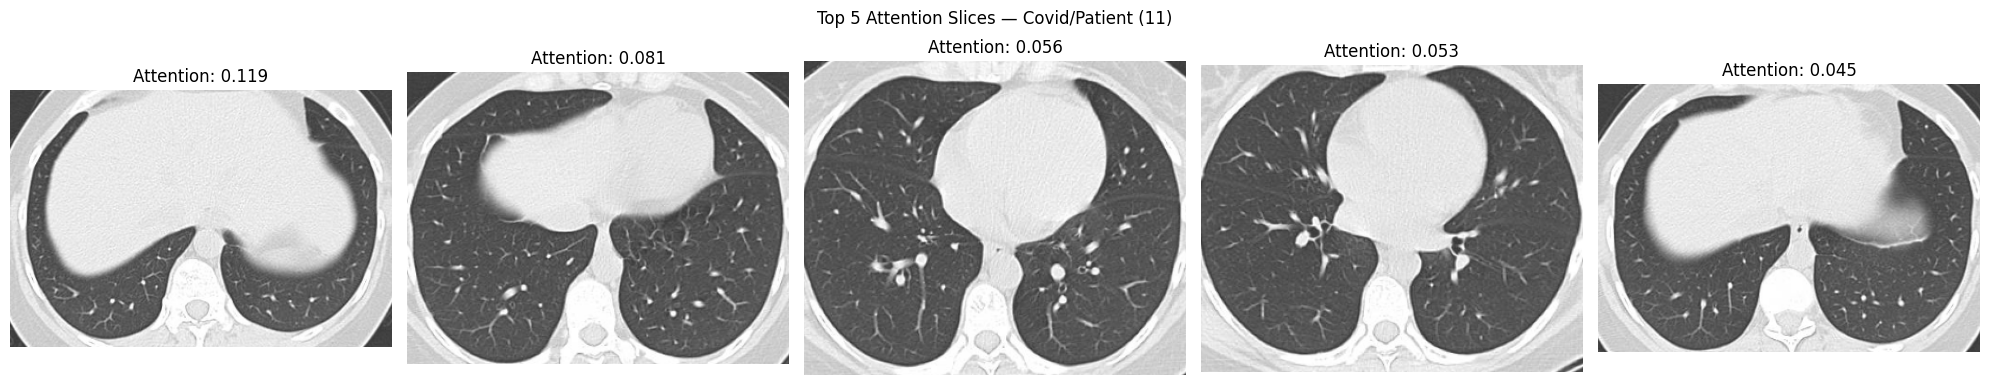

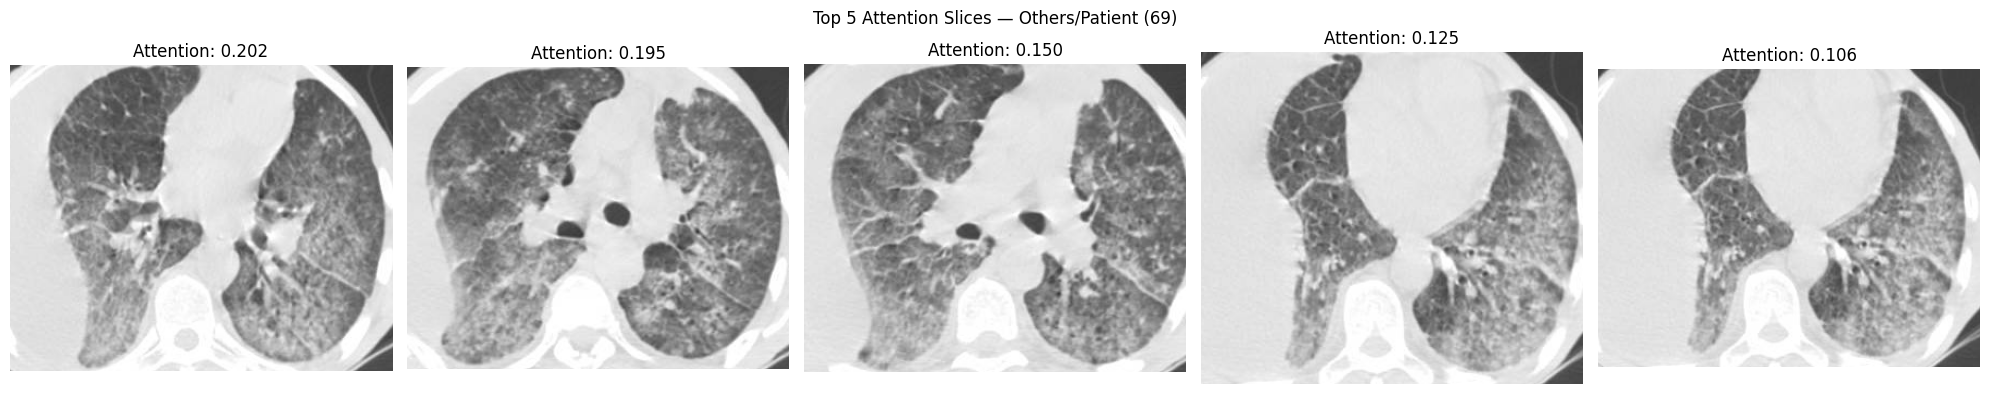

In [28]:
import matplotlib.pyplot as plt
from PIL import Image

def visualize_patient_attention(patient_id, top_n=5):

    patient_data = (
        attention_df[
            attention_df["patient_id"] == patient_id
        ]
        .sort_values("attention_weight", ascending=False)
        .head(top_n)
    )

    fig, axes = plt.subplots(
        1, len(patient_data),
        figsize=(4 * len(patient_data), 4)
    )

    if len(patient_data) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, patient_data.iterrows()):

        image = Image.open(row["image_path"]).convert("RGB")

        ax.imshow(image)
        ax.set_title(
            f"Attention: {row['attention_weight']:.3f}"
        )
        ax.axis("off")

    plt.suptitle(
        f"Top {top_n} Attention Slices — {patient_id}"
    )
    plt.tight_layout()
    plt.show()


visualize_patient_attention("Covid/Patient (11)")
visualize_patient_attention("Others/Patient (69)")

In [29]:
attention_sums = (
    attention_df
    .groupby("patient_id")["attention_weight"]
    .sum()
)

print("Attention weight statistics:")
print(attention_sums.describe())

print(
    "\nMaximum deviation from 1:",
    abs(attention_sums - 1).max()
)

assert np.allclose(attention_sums.values, 1.0, atol=1e-5)

print("\nAll attention distributions are valid.")

Attention weight statistics:
count    3.200000e+01
mean     1.000000e+00
std      3.501899e-08
min      9.999999e-01
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: attention_weight, dtype: float64

Maximum deviation from 1: 9.825453162193298e-08

All attention distributions are valid.


In [30]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np
import pandas as pd

# Load saved ResNet-18 slice predictions and probabilities
resnet_slices = pd.read_csv(
    RESULTS_DIR / "test_predictions.csv"
)

resnet_probs = np.load(
    RESULTS_DIR / "test_probabilities.npy"
)

assert len(resnet_slices) == len(resnet_probs)

# Attach probabilities to their corresponding slices
resnet_slices = resnet_slices.reset_index(drop=True)

resnet_slices["prob_covid"] = resnet_probs[:, 0]
resnet_slices["prob_healthy"] = resnet_probs[:, 1]
resnet_slices["prob_others"] = resnet_probs[:, 2]

# Average slice probabilities for each patient
resnet_patient = (
    resnet_slices.groupby("patient_id")
    .agg(
        true_label=("label", "first"),
        prob_covid=("prob_covid", "mean"),
        prob_healthy=("prob_healthy", "mean"),
        prob_others=("prob_others", "mean")
    )
    .reset_index()
)

prob_columns = [
    "prob_covid", "prob_healthy", "prob_others"
]

resnet_patient["resnet_prediction"] = (
    resnet_patient[prob_columns]
    .to_numpy()
    .argmax(axis=1)
)

resnet_patient["true_idx"] = (
    resnet_patient["true_label"].map(class_to_idx)
)

print("ResNet-18 patient accuracy:",
      accuracy_score(
          resnet_patient["true_idx"],
          resnet_patient["resnet_prediction"]
      ))

print("ResNet-18 patient macro-F1:",
      f1_score(
          resnet_patient["true_idx"],
          resnet_patient["resnet_prediction"],
          average="macro"
      ))

print("Number of test patients:", len(resnet_patient))

ResNet-18 patient accuracy: 0.78125
ResNet-18 patient macro-F1: 0.7746880570409983
Number of test patients: 32


In [31]:
# Create MIL patient prediction table
mil_patient = pd.DataFrame({
    "patient_id": [b["patient_id"] for b in test_bags],
    "true_idx": test_true_labels,
    "mil_prediction": test_predictions
})

# Join both models' predictions
comparison = resnet_patient[
    ["patient_id", "true_idx", "resnet_prediction"]
].merge(
    mil_patient,
    on=["patient_id", "true_idx"],
    how="inner",
    validate="one_to_one"
)

comparison["true_label"] = comparison["true_idx"].map(
    {0: "Covid", 1: "Healthy", 2: "Others"}
)

comparison["resnet_correct"] = (
    comparison["resnet_prediction"] == comparison["true_idx"]
)

comparison["mil_correct"] = (
    comparison["mil_prediction"] == comparison["true_idx"]
)

comparison["resnet_label"] = comparison["resnet_prediction"].map(
    {0: "Covid", 1: "Healthy", 2: "Others"}
)

comparison["mil_label"] = comparison["mil_prediction"].map(
    {0: "Covid", 1: "Healthy", 2: "Others"}
)

print("Patients evaluated:", len(comparison))

print("\nComparison summary:")
print(pd.crosstab(
    comparison["resnet_correct"],
    comparison["mil_correct"],
    rownames=["ResNet correct"],
    colnames=["MIL correct"]
))

print("\nMIL corrected, ResNet wrong:")
display(comparison[
    (~comparison["resnet_correct"]) &
    (comparison["mil_correct"])
])

print("\nResNet corrected, MIL wrong:")
display(comparison[
    (comparison["resnet_correct"]) &
    (~comparison["mil_correct"])
])

print("\nBoth models wrong:")
display(comparison[
    (~comparison["resnet_correct"]) &
    (~comparison["mil_correct"])
])

comparison.to_csv(
    RESULTS_DIR / "resnet_vs_mil_patient_comparison.csv",
    index=False
)

print("\nComparison saved.")

Patients evaluated: 32

Comparison summary:
MIL correct     False  True 
ResNet correct              
False               5      2
True                2     23

MIL corrected, ResNet wrong:


,patient_id,true_idx,resnet_prediction,mil_prediction,true_label,resnet_correct,mil_correct,resnet_label,mil_label
8,Covid/Patient (61),0,2,0,Covid,False,True,Others,Covid
27,Others/Patient (55),2,1,2,Others,False,True,Healthy,Others



ResNet corrected, MIL wrong:


,patient_id,true_idx,resnet_prediction,mil_prediction,true_label,resnet_correct,mil_correct,resnet_label,mil_label
22,Others/Patient (22),2,2,0,Others,True,False,Others,Covid
25,Others/Patient (47),2,2,1,Others,True,False,Others,Healthy



Both models wrong:


,patient_id,true_idx,resnet_prediction,mil_prediction,true_label,resnet_correct,mil_correct,resnet_label,mil_label
0,Covid/Patient (11),0,1,1,Covid,False,False,Healthy,Healthy
6,Covid/Patient (49),0,1,1,Covid,False,False,Healthy,Healthy
15,Healthy/Patient (31),1,2,2,Healthy,False,False,Others,Others
18,Healthy/Patient (5),1,2,2,Healthy,False,False,Others,Others
31,Others/Patient (69),2,0,0,Others,False,False,Covid,Covid



Comparison saved.


In [32]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_true = comparison["true_idx"]

resnet_pred = comparison["resnet_prediction"]
mil_pred = comparison["mil_prediction"]

for name, predictions in [
    ("ResNet-18", resnet_pred),
    ("Attention MIL", mil_pred)
]:

    print(f"\n{'='*45}")
    print(name)
    print("="*45)

    print("Accuracy:",
          accuracy_score(y_true, predictions))

    print("Macro-F1:",
          f1_score(y_true, predictions, average="macro"))

    print("\nClassification report:")
    print(classification_report(
        y_true,
        predictions,
        labels=[0, 1, 2],
        target_names=["Covid", "Healthy", "Others"],
        zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1, 2]
    ))


ResNet-18
Accuracy: 0.78125
Macro-F1: 0.7746880570409983

Classification report:
              precision    recall  f1-score   support

       Covid       0.90      0.75      0.82        12
     Healthy       0.67      0.75      0.71         8
      Others       0.77      0.83      0.80        12

    accuracy                           0.78        32
   macro avg       0.78      0.78      0.77        32
weighted avg       0.79      0.78      0.78        32

Confusion matrix:
[[ 9  2  1]
 [ 0  6  2]
 [ 1  1 10]]

Attention MIL
Accuracy: 0.78125
Macro-F1: 0.773941460642228

Classification report:
              precision    recall  f1-score   support

       Covid       0.83      0.83      0.83        12
     Healthy       0.67      0.75      0.71         8
      Others       0.82      0.75      0.78        12

    accuracy                           0.78        32
   macro avg       0.77      0.78      0.77        32
weighted avg       0.79      0.78      0.78        32

Confusion matrix

In [33]:
print("ResNet patients:", resnet_patient["patient_id"].nunique())
print("MIL patients:", mil_patient["patient_id"].nunique())
print("Comparison patients:", comparison["patient_id"].nunique())

print(
    "Label mismatches:",
    (resnet_patient["true_idx"] !=
     resnet_patient["patient_id"].map(
         comparison.set_index("patient_id")["true_idx"]
     )).sum()
)

ResNet patients: 32
MIL patients: 32
Comparison patients: 32
Label mismatches: 0


In [34]:
from pathlib import Path
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

FINAL_RESULTS_DIR = RESULTS_DIR / "final_project_results"
FINAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Final results directory:", FINAL_RESULTS_DIR)

Final results directory: /content/drive/MyDrive/chest_ct_classifier/results/final_project_results


In [35]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_true = comparison["true_idx"].to_numpy()

model_predictions = {
    "ResNet18_reconstructed": comparison["resnet_prediction"].to_numpy(),
    "Attention_MIL": comparison["mil_prediction"].to_numpy()
}

final_metrics = {}

for model_name, predictions in model_predictions.items():

    final_metrics[model_name] = {
        "accuracy": float(accuracy_score(y_true, predictions)),
        "macro_f1": float(f1_score(
            y_true, predictions, average="macro"
        )),
        "weighted_f1": float(f1_score(
            y_true, predictions, average="weighted"
        )),
        "classification_report": classification_report(
            y_true,
            predictions,
            labels=[0, 1, 2],
            target_names=["Covid", "Healthy", "Others"],
            output_dict=True,
            zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            y_true, predictions, labels=[0, 1, 2]
        ).tolist()
    }

# Save metrics as JSON
with open(FINAL_RESULTS_DIR / "final_metrics.json", "w") as f:
    json.dump(final_metrics, f, indent=4)

# Save a concise comparison CSV
summary = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": values["accuracy"],
        "Macro_F1": values["macro_f1"],
        "Weighted_F1": values["weighted_f1"]
    }
    for name, values in final_metrics.items()
])

summary.to_csv(
    FINAL_RESULTS_DIR / "model_comparison.csv",
    index=False
)

# Save patient-level predictions
comparison.to_csv(
    FINAL_RESULTS_DIR / "patient_level_comparison.csv",
    index=False
)

# Copy attention weights into the final folder
attention_df.to_csv(
    FINAL_RESULTS_DIR / "mil_attention_weights.csv",
    index=False
)

# Save MIL test probabilities
np.save(
    FINAL_RESULTS_DIR / "mil_test_probabilities.npy",
    test_probabilities
)

display(summary)
print("Comparison files saved.")

,Model,Accuracy,Macro_F1,Weighted_F1
0,ResNet18_reconstructed,0.78125,0.774688,0.783289
1,Attention_MIL,0.78125,0.773941,0.782449


Comparison files saved.


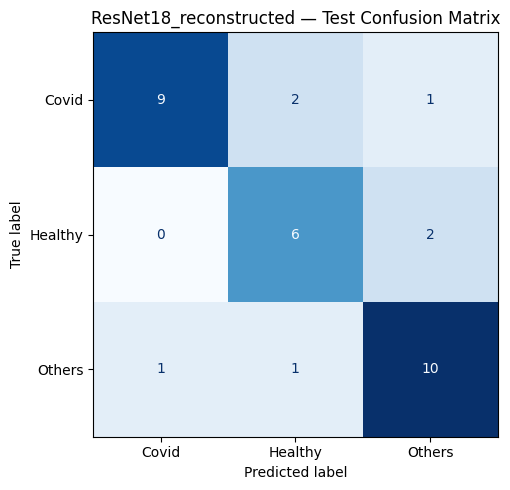

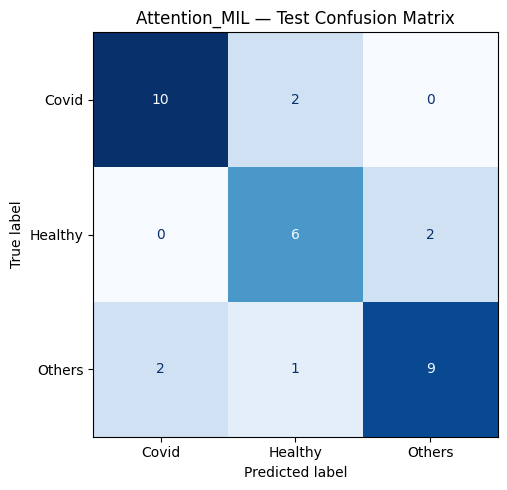

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["Covid", "Healthy", "Others"]

for model_name, predictions in model_predictions.items():

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1, 2]
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    display_cm.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{model_name} — Test Confusion Matrix")
    plt.tight_layout()

    filename = f"{model_name.lower()}_confusion_matrix.png"

    plt.savefig(
        FINAL_RESULTS_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

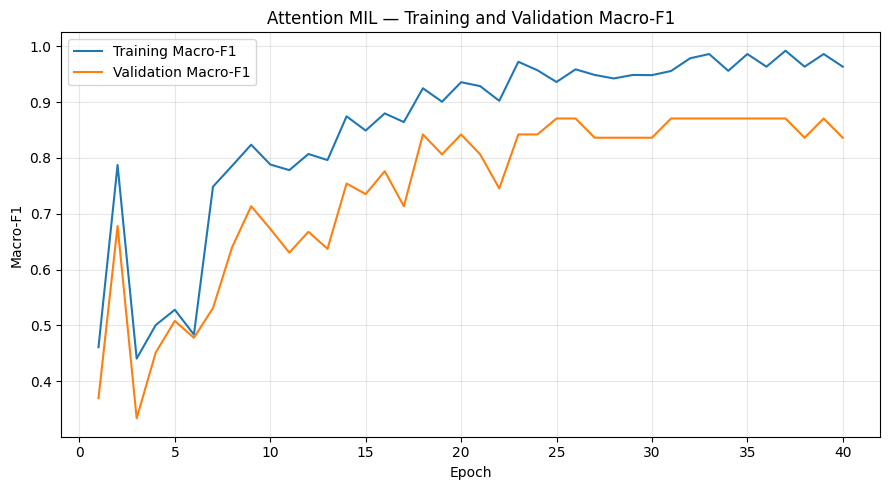

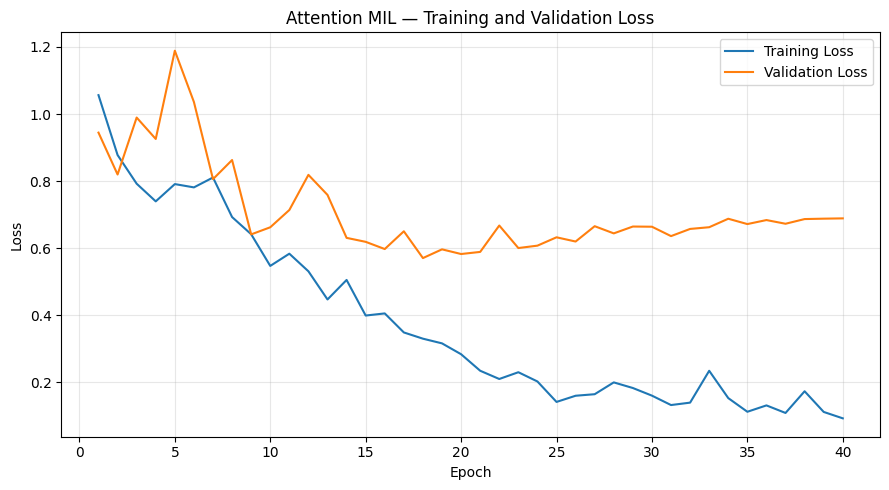

In [37]:
mil_history_df = pd.read_csv(
    RESULTS_DIR / "mil_training_history.csv"
)

# Macro-F1
plt.figure(figsize=(9, 5))

plt.plot(
    mil_history_df["epoch"],
    mil_history_df["train_macro_f1"],
    label="Training Macro-F1"
)

plt.plot(
    mil_history_df["epoch"],
    mil_history_df["val_macro_f1"],
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("Attention MIL — Training and Validation Macro-F1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FINAL_RESULTS_DIR / "mil_f1_curve.png",
    dpi=300
)

plt.show()


# Loss
plt.figure(figsize=(9, 5))

plt.plot(
    mil_history_df["epoch"],
    mil_history_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    mil_history_df["epoch"],
    mil_history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Attention MIL — Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FINAL_RESULTS_DIR / "mil_loss_curve.png",
    dpi=300
)

plt.show()

In [38]:
project_summary = {
    "project": "AI-Based Chest CT Classification using Transfer Learning and Attention MIL",
    "dataset": "Soares and Angelov SARS-CoV-2 CT Scan Dataset",
    "total_images_after_duplicate_exclusion": 4169,
    "total_patient_folders": 210,
    "splits": {
        "train_patients": 147,
        "validation_patients": 31,
        "test_patients": 32
    },
    "classes": ["Covid", "Healthy", "Others"],
    "baseline": {
        "architecture": "ResNet-18",
        "approach": "Slice-level classification followed by mean probability aggregation",
        "status": "Reconstructed from saved test slice probabilities; earlier reported result differs and requires audit"
    },
    "mil": {
        "architecture": "Attention-based Multiple Instance Learning",
        "feature_extractor": "Frozen Phase 2 ResNet-18",
        "feature_dimension": 512,
        "attention_dimension": 128,
        "best_validation_macro_f1": float(best_val_f1),
        "best_epoch": int(best_epoch)
    },
    "test_results": {
        "resnet18_reconstructed_accuracy": float(
            final_metrics["ResNet18_reconstructed"]["accuracy"]
        ),
        "resnet18_reconstructed_macro_f1": float(
            final_metrics["ResNet18_reconstructed"]["macro_f1"]
        ),
        "mil_accuracy": float(
            final_metrics["Attention_MIL"]["accuracy"]
        ),
        "mil_macro_f1": float(
            final_metrics["Attention_MIL"]["macro_f1"]
        )
    },
    "limitations": [
        "Only 32 patients in the held-out test set.",
        "Patient identifiers use class-qualified folder names; original patient identity conventions need verification.",
        "MIL uses features from a ResNet-18 trained with slice-level supervision.",
        "Attention weights are not clinical explanations.",
        "Results are experimental and not intended for medical diagnosis.",
        "Earlier ResNet-18 patient-level evaluation differs from the reconstructed evaluation and requires investigation."
    ]
}

with open(
    FINAL_RESULTS_DIR / "project_experiment_summary.json",
    "w"
) as f:
    json.dump(project_summary, f, indent=4)

print("Experiment summary saved.")

Experiment summary saved.


In [39]:
print("FINAL PROJECT RESULTS")
print("=====================")

for file in sorted(FINAL_RESULTS_DIR.iterdir()):
    if file.is_file():
        print(f"{file.name:45s} {file.stat().st_size / 1024:.1f} KB")

FINAL PROJECT RESULTS
attention_mil_confusion_matrix.png            67.4 KB
final_metrics.json                            3.0 KB
mil_attention_weights.csv                     110.3 KB
mil_f1_curve.png                              194.0 KB
mil_loss_curve.png                            172.9 KB
mil_test_probabilities.npy                    0.5 KB
model_comparison.csv                          0.2 KB
patient_level_comparison.csv                  1.9 KB
project_experiment_summary.json               1.7 KB
resnet18_reconstructed_confusion_matrix.png   73.3 KB


In [40]:
from sklearn.metrics import accuracy_score, f1_score
from collections import Counter

# Load saved slice predictions
resnet_slices = pd.read_csv(
    RESULTS_DIR / "test_predictions.csv"
)

resnet_probs = np.load(
    RESULTS_DIR / "test_probabilities.npy"
)

assert len(resnet_slices) == len(resnet_probs)

# Attach probabilities
resnet_slices = resnet_slices.reset_index(drop=True)

resnet_slices["p_covid"] = resnet_probs[:, 0]
resnet_slices["p_healthy"] = resnet_probs[:, 1]
resnet_slices["p_others"] = resnet_probs[:, 2]

# Check label consistency within every patient
assert (
    resnet_slices.groupby("patient_id")["label"].nunique().max()
    == 1
)

# Method 1: Mean probability aggregation
mean_prob = (
    resnet_slices.groupby("patient_id")
    [["p_covid", "p_healthy", "p_others"]]
    .mean()
)

mean_prob_pred = mean_prob.to_numpy().argmax(axis=1)

# Method 2: Majority vote across slice predictions
majority_pred = (
    resnet_slices.groupby("patient_id")["predicted_idx"]
    .agg(lambda x: Counter(x).most_common(1)[0][0])
)

# Method 3: Mean of one-hot slice predictions
# Equivalent to majority vote, with argmax resolving ties by lowest class index
one_hot = np.eye(3)[resnet_slices["predicted_idx"].astype(int)]

one_hot_df = pd.DataFrame(
    one_hot,
    columns=["covid", "healthy", "others"]
)
one_hot_df["patient_id"] = resnet_slices["patient_id"].values

majority_mean = (
    one_hot_df.groupby("patient_id")[["covid", "healthy", "others"]]
    .mean()
)

majority_mean_pred = majority_mean.to_numpy().argmax(axis=1)

# Ground truth, one label per patient
patient_truth = (
    resnet_slices.groupby("patient_id")["label"]
    .first()
    .map(class_to_idx)
)

# Align all predictions by patient ID
audit = pd.DataFrame({
    "true": patient_truth,
    "mean_probability": mean_prob_pred,
    "majority_vote": majority_pred.reindex(patient_truth.index).values,
    "one_hot_mean": majority_mean_pred
}, index=patient_truth.index)

print("AGGREGATION AUDIT")
print("=================")

for method in [
    "mean_probability",
    "majority_vote",
    "one_hot_mean"
]:
    print(
        f"{method:20s} "
        f"Accuracy = {accuracy_score(audit['true'], audit[method]):.4f} | "
        f"Macro-F1 = {f1_score(audit['true'], audit[method], average='macro'):.4f}"
    )

print("\nDo majority vote and one-hot mean agree?")
print(
    np.array_equal(
        audit["majority_vote"].values,
        audit["one_hot_mean"].values
    )
)

audit.to_csv(
    FINAL_RESULTS_DIR / "resnet_aggregation_audit.csv"
)

AGGREGATION AUDIT
mean_probability     Accuracy = 0.7812 | Macro-F1 = 0.7747
majority_vote        Accuracy = 0.7500 | Macro-F1 = 0.7449
one_hot_mean         Accuracy = 0.7500 | Macro-F1 = 0.7449

Do majority vote and one-hot mean agree?
True


In [42]:
%cd /content
!git clone https://github.com/suzanne-jolly/Chest-CT-Classifier.git
%cd /content/Chest-CT-Classifier

/content
Cloning into 'Chest-CT-Classifier'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.
/content/Chest-CT-Classifier


In [43]:
import os

REPO_DIR = "/content/Chest-CT-Classifier"

os.chdir(REPO_DIR)

print("Current folder:", os.getcwd())
print("Files:", os.listdir())

Current folder: /content/Chest-CT-Classifier
Files: ['.git', 'README.md']


In [45]:
%%writefile .gitignore
# Dataset and extracted images
data/
**/New_Data_CoV2/
*.dcm

# Model checkpoints
models/*.pth
models/*.pt
*.ckpt
*.h5

# Python / Colab
__pycache__/
*.pyc
.ipynb_checkpoints/

# Secrets
.env
.env.*
credentials.json

# Temporary files
.DS_Store
*.log

Overwriting .gitignore


In [46]:
import os

folders = [
    "notebooks",
    "src",
    "results",
    "models"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created.")

Project folders created.


In [47]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [48]:
!find "/content/drive/MyDrive" -maxdepth 4 -name "*.ipynb"

/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/Chilika_data.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb
/content/drive/MyDrive/Colab Notebooks/Credit Card Risk Assessment.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled3.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled4.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled5.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled6.ipynb
/content/drive/MyDrive/Colab Notebooks/rag_from_scratch_10_and_11.ipynb
/content/drive/MyDrive/Colab Notebooks/rag_from_scratch_1_to_4.ipynb
/content/drive/MyDrive/Colab Notebooks/Pandas_Practice.ipynb
/content/drive/MyDrive/Colab Notebooks/chest_ct_classifier.ipynb


In [49]:
!find "/content/drive/MyDrive/chest_ct_classifier" -maxdepth 4 -type f | head -80

/content/drive/MyDrive/chest_ct_classifier/data/raw/covid_ctscan.zip
/content/drive/MyDrive/chest_ct_classifier/data/processed/image_manifest.csv
/content/drive/MyDrive/chest_ct_classifier/data/processed/patient_splits.csv
/content/drive/MyDrive/chest_ct_classifier/data/processed/image_manifest_clean.csv
/content/drive/MyDrive/chest_ct_classifier/data/processed/final_split_manifest.csv
/content/drive/MyDrive/chest_ct_classifier/models/resnet18_phase1_best.pth
/content/drive/MyDrive/chest_ct_classifier/models/resnet18_phase2_best.pth
/content/drive/MyDrive/chest_ct_classifier/models/attention_mil_best.pth
/content/drive/MyDrive/chest_ct_classifier/results/phase1_training_history.csv
/content/drive/MyDrive/chest_ct_classifier/results/phase2_training_history.csv
/content/drive/MyDrive/chest_ct_classifier/results/test_predictions.csv
/content/drive/MyDrive/chest_ct_classifier/results/test_probabilities.npy
/content/drive/MyDrive/chest_ct_classifier/results/slice_features_phase2.npy
/conten

In [50]:
%%writefile requirements.txt
torch
torchvision
numpy
pandas
scikit-learn
matplotlib
seaborn
Pillow
tqdm

Writing requirements.txt


In [51]:
!git status --short

?? .gitignore
?? requirements.txt


In [52]:
from getpass import getpass
import subprocess

token = getpass("Paste your GitHub token: ")

subprocess.run(
    ["git", "config", "--global", "credential.helper", "store"],
    check=True
)

credential = (
    "protocol=https\n"
    "host=github.com\n"
    "username=suzanne-jolly\n"
    f"password={token}\n\n"
)

subprocess.run(
    ["git", "credential", "approve"],
    input=credential,
    text=True,
    check=True
)

del token
print("GitHub authentication configured for this Colab runtime.")

Paste your GitHub token: ··········
GitHub authentication configured for this Colab runtime.


In [53]:
%cd /content/Chest-CT-Classifier

!git add .gitignore README.md requirements.txt notebooks/ src/ results/
!git status

/content/Chest-CT-Classifier
On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   .gitignore
	new file:   requirements.txt



In [54]:
!git commit -m "Add chest CT classification project"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@9e7cffc0c2e8.(none)')


In [55]:
!git branch --show-current

main


In [56]:
!git push -u origin main

branch 'main' set up to track 'origin/main'.
Everything up-to-date


In [57]:
%cd /content/Chest-CT-Classifier

!git status
!git log -1 --oneline
!git remote -v

/content/Chest-CT-Classifier
On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   .gitignore
	new file:   requirements.txt

8f89ab2 (HEAD -> main, origin/main, origin/HEAD) Initialize README with project details
origin	https://github.com/suzanne-jolly/Chest-CT-Classifier.git (fetch)
origin	https://github.com/suzanne-jolly/Chest-CT-Classifier.git (push)


In [58]:
%cd /content/Chest-CT-Classifier

!git commit -m "Add project dependencies and gitignore"

/content/Chest-CT-Classifier
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@9e7cffc0c2e8.(none)')


In [59]:
!git config --global user.name "Suzanne Jolly"
!git config --global user.email "am1241079@iitd.ac.in"

In [60]:
!git config --global user.name
!git config --global user.email

Suzanne Jolly
am1241079@iitd.ac.in


In [61]:
%cd /content/Chest-CT-Classifier

!git commit -m "Add project dependencies and gitignore"
!git push origin main

/content/Chest-CT-Classifier
[main c4fbafb] Add project dependencies and gitignore
 2 files changed, 33 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 requirements.txt
Enumerating objects: 5, done.
Counting objects: 100% (5/5), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 596 bytes | 596.00 KiB/s, done.
Total 4 (delta 0), reused 0 (delta 0), pack-reused 0
To https://github.com/suzanne-jolly/Chest-CT-Classifier.git
   8f89ab2..c4fbafb  main -> main


In [62]:
!find "/content/drive/MyDrive/chest_ct_classifier" -name "*.ipynb"

In [63]:
!find "/content/drive/MyDrive/chest_ct_classifier" -path "*final_project_results*" -type f

/content/drive/MyDrive/chest_ct_classifier/results/final_project_results/final_metrics.json
/content/drive/MyDrive/chest_ct_classifier/results/final_project_results/model_comparison.csv
/content/drive/MyDrive/chest_ct_classifier/results/final_project_results/patient_level_comparison.csv
/content/drive/MyDrive/chest_ct_classifier/results/final_project_results/mil_attention_weights.csv
/content/drive/MyDrive/chest_ct_classifier/results/final_project_results/mil_test_probabilities.npy
/content/drive/MyDrive/chest_ct_classifier/results/final_project_results/resnet18_reconstructed_confusion_matrix.png
/content/drive/MyDrive/chest_ct_classifier/results/final_project_results/attention_mil_confusion_matrix.png
/content/drive/MyDrive/chest_ct_classifier/results/final_project_results/mil_f1_curve.png
/content/drive/MyDrive/chest_ct_classifier/results/final_project_results/mil_loss_curve.png
/content/drive/MyDrive/chest_ct_classifier/results/final_project_results/project_experiment_summary.json
/

In [64]:
import os
import shutil

SOURCE = "/content/drive/MyDrive/chest_ct_classifier/results/final_project_results"
DEST = "/content/Chest-CT-Classifier/results/final_project_results"

os.makedirs(DEST, exist_ok=True)

for filename in os.listdir(SOURCE):
    source_file = os.path.join(SOURCE, filename)
    dest_file = os.path.join(DEST, filename)

    if os.path.isfile(source_file):
        shutil.copy2(source_file, dest_file)

print("Copied files:")
print(os.listdir(DEST))

Copied files:
['attention_mil_confusion_matrix.png', 'patient_level_comparison.csv', 'resnet_aggregation_audit.csv', 'mil_attention_weights.csv', 'resnet18_reconstructed_confusion_matrix.png', 'mil_test_probabilities.npy', 'mil_loss_curve.png', 'project_experiment_summary.json', 'mil_f1_curve.png', 'final_metrics.json', 'model_comparison.csv']


In [65]:
%cd /content/Chest-CT-Classifier

!git status --short

/content/Chest-CT-Classifier
?? results/


In [66]:
!git add results/final_project_results/
!git status

On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   results/final_project_results/attention_mil_confusion_matrix.png
	new file:   results/final_project_results/final_metrics.json
	new file:   results/final_project_results/mil_attention_weights.csv
	new file:   results/final_project_results/mil_f1_curve.png
	new file:   results/final_project_results/mil_loss_curve.png
	new file:   results/final_project_results/mil_test_probabilities.npy
	new file:   results/final_project_results/model_comparison.csv
	new file:   results/final_project_results/patient_level_comparison.csv
	new file:   results/final_project_results/project_experiment_summary.json
	new file:   results/final_project_results/resnet18_reconstructed_confusion_matrix.png
	new file:   results/final_project_results/resnet_aggregation_audit.csv



In [67]:
!git commit -m "Add final model evaluation results"
!git push origin main

[main 2568481] Add final model evaluation results
 11 files changed, 840 insertions(+)
 create mode 100644 results/final_project_results/attention_mil_confusion_matrix.png
 create mode 100644 results/final_project_results/final_metrics.json
 create mode 100644 results/final_project_results/mil_attention_weights.csv
 create mode 100644 results/final_project_results/mil_f1_curve.png
 create mode 100644 results/final_project_results/mil_loss_curve.png
 create mode 100644 results/final_project_results/mil_test_probabilities.npy
 create mode 100644 results/final_project_results/model_comparison.csv
 create mode 100644 results/final_project_results/patient_level_comparison.csv
 create mode 100644 results/final_project_results/project_experiment_summary.json
 create mode 100644 results/final_project_results/resnet18_reconstructed_confusion_matrix.png
 create mode 100644 results/final_project_results/resnet_aggregation_audit.csv
Enumerating objects: 16, done.
Counting objects: 100% (16/16), do

In [68]:
!find "/content/drive/MyDrive" -type f -name "*.ipynb"

/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/Chilika_data.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb
/content/drive/MyDrive/Colab Notebooks/Credit Card Risk Assessment.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled3.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled4.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled5.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled6.ipynb
/content/drive/MyDrive/Colab Notebooks/rag_from_scratch_10_and_11.ipynb
/content/drive/MyDrive/Colab Notebooks/rag_from_scratch_1_to_4.ipynb
/content/drive/MyDrive/Colab Notebooks/Pandas_Practice.ipynb
/content/drive/MyDrive/Colab Notebooks/chest_ct_classifier.ipynb
